# Análisis exploratorio de datos (EDA)

**Objetivo:** predecir `Frio (Kw)` del día D+1 con información disponible al finalizar D.

Se exploran tres Excel con totalizadores horarios. El consumo diario se toma a las **23:59**. Este notebook identifica problemas de calidad y variables candidatas; **no realiza limpieza definitiva ni entrenamiento**.

**Nota:** se mantiene el nombre `Frio (Kw)` de la fuente, aunque la unidad física de un totalizador acumulado requiere confirmación. Las correlaciones son descriptivas, no validación predictiva.


## 1. Configuración y dependencias

Los tres Excel se leen desde `data/` por nombre, sin modificar los originales.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path.cwd()
if ROOT.name.lower() == "notebooks":
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data"

ARCHIVOS = [
    "Totalizadores Planta 2020_2022.xlsx",
    "Totalizadores Planta - 2021_2023.xlsx",
    "Totalizadores Planta 2022_2023.xlsx",
]

archivos = [DATA_DIR / nombre for nombre in ARCHIVOS]

for nombre in ARCHIVOS:
    ruta = DATA_DIR / nombre
    if not ruta.is_file():
        raise FileNotFoundError(
            f"No se encontró {ruta}. Colocá los Excel sin renombrar dentro de data/."
        )

print("Raíz del proyecto:", ROOT)
print("Pandas:", pd.__version__)


Raíz del proyecto: c:\Users\maxim\OneDrive\Desktop\tp-final
Pandas: 3.1.1


## 2. Inventario de los Excel

Recuento de hojas, dimensiones y períodos disponibles en cada archivo.


In [2]:
filas_inventario = []
for nombre in ARCHIVOS:
    ruta = DATA_DIR / nombre
    with pd.ExcelFile(ruta) as xls:
        for hoja in xls.sheet_names:
            filas_inventario.append({"archivo": nombre, "hoja": hoja})

inventario_hojas = pd.DataFrame(filas_inventario)
resumen_hojas = (
    inventario_hojas.groupby("archivo", as_index=False)
    .agg(cantidad_hojas=("hoja", "size"))
)
display(resumen_hojas)
display(inventario_hojas)

,archivo,cantidad_hojas
0,Totalizadores Planta - 2021_2023.xlsx,16
1,Totalizadores Planta 2020_2022.xlsx,15
2,Totalizadores Planta 2022_2023.xlsx,15


,archivo,hoja
0,Totalizadores Planta 2020_2022.xlsx,Consolidado KPI
1,Totalizadores Planta 2020_2022.xlsx,Consolidado Produccion
2,Totalizadores Planta 2020_2022.xlsx,Totalizadores Produccion
3,Totalizadores Planta 2020_2022.xlsx,Consolidado EE
4,Totalizadores Planta 2020_2022.xlsx,Totalizadores Energia
5,Totalizadores Planta 2020_2022.xlsx,Consolidado Agua
6,Totalizadores Planta 2020_2022.xlsx,Totalizadores Agua
7,Totalizadores Planta 2020_2022.xlsx,Consolidado GasVapor
8,Totalizadores Planta 2020_2022.xlsx,Totalizadores Gas y Vapor
9,Totalizadores Planta 2020_2022.xlsx,Consolidado Aire


## 3. Esquemas y columnas redundantes

Se comparan las columnas entre archivos para detectar diferencias y posibles duplicados.


In [3]:
# Comparación de columnas entre los tres archivos

hojas = [
    "Consolidado EE",
    "Consolidado Produccion",
    "Totalizadores Energia",
    "Consolidado KPI"
]

columnas_por_archivo = {}
resumen = []

for archivo in archivos:

    with pd.ExcelFile(archivo) as excel:

        for hoja in hojas:

            if hoja not in excel.sheet_names:
                print(f"Falta {hoja} en {archivo.name}")
                continue

            df = pd.read_excel(
                excel,
                sheet_name=hoja,
                nrows=0
            )

            columnas = set(
                df.columns.astype(str).str.strip()
            )

            columnas_por_archivo[(archivo.name, hoja)] = columnas

            resumen.append({
                "archivo": archivo.name,
                "hoja": hoja,
                "cantidad_columnas": len(columnas)
            })

display(pd.DataFrame(resumen))

# Comparar diferencias entre archivos
for hoja in hojas:

    print(f"\n{'=' * 55}")
    print(f"HOJA: {hoja}")

    disponibles = {
        archivo: columnas
        for (archivo, nombre_hoja), columnas
        in columnas_por_archivo.items()
        if nombre_hoja == hoja
    }

    if len(disponibles) < 2:
        print("No hay suficientes archivos para comparar.")
        continue

    columnas_comunes = set.intersection(
        *disponibles.values()
    )

    print("Columnas comunes:", len(columnas_comunes))

    for archivo, columnas in disponibles.items():

        exclusivas = columnas - columnas_comunes

        print(f"\n{archivo}")
        print("Columnas no comunes:", len(exclusivas))

        if exclusivas:
            print(sorted(exclusivas))


,archivo,hoja,cantidad_columnas
0,Totalizadores Planta 2020_2022.xlsx,Consolidado EE,21
1,Totalizadores Planta 2020_2022.xlsx,Consolidado Produccion,12
2,Totalizadores Planta 2020_2022.xlsx,Totalizadores Energia,53
3,Totalizadores Planta 2020_2022.xlsx,Consolidado KPI,62
4,Totalizadores Planta - 2021_2023.xlsx,Consolidado EE,21
5,Totalizadores Planta - 2021_2023.xlsx,Consolidado Produccion,13
6,Totalizadores Planta - 2021_2023.xlsx,Totalizadores Energia,59
7,Totalizadores Planta - 2021_2023.xlsx,Consolidado KPI,123
8,Totalizadores Planta 2022_2023.xlsx,Consolidado EE,21
9,Totalizadores Planta 2022_2023.xlsx,Consolidado Produccion,18



HOJA: Consolidado EE
Columnas comunes: 21

Totalizadores Planta 2020_2022.xlsx
Columnas no comunes: 0

Totalizadores Planta - 2021_2023.xlsx
Columnas no comunes: 0

Totalizadores Planta 2022_2023.xlsx
Columnas no comunes: 0

HOJA: Consolidado Produccion
Columnas comunes: 12

Totalizadores Planta 2020_2022.xlsx
Columnas no comunes: 0

Totalizadores Planta - 2021_2023.xlsx
Columnas no comunes: 1
['Hl de Mosto Copia']

Totalizadores Planta 2022_2023.xlsx
Columnas no comunes: 6
['Hl de Mosto Copia', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18']

HOJA: Totalizadores Energia
Columnas comunes: 53

Totalizadores Planta 2020_2022.xlsx
Columnas no comunes: 0

Totalizadores Planta - 2021_2023.xlsx
Columnas no comunes: 6
['Unnamed: 53', 'Unnamed: 54', 'Unnamed: 55', 'Unnamed: 56', 'Unnamed: 57', 'Unnamed: 58']

Totalizadores Planta 2022_2023.xlsx
Columnas no comunes: 1
['Id']

HOJA: Consolidado KPI
Columnas comunes: 61

Totalizadores Planta 2020_2022.xlsx
Columnas no 

### Comparación de esquemas

- `Consolidado EE`: **21 columnas comunes**.
- `Consolidado Produccion`: **12 comunes** y columnas adicionales.
- `Totalizadores Energia`: **53 comunes**; diferencias en `Id` y columnas auxiliares.
- `Consolidado KPI`: mayor variación, principalmente por columnas de metas.

La armonización de esquemas queda para el preprocesamiento.


In [4]:

# Auditar las columnas adicionales de cada hoja
# Sin modificar los archivos originales

import pandas as pd

resultados = []

for hoja in hojas:

    # Columnas comunes a los tres archivos
    conjuntos = [
        columnas
        for (nombre_archivo, nombre_hoja), columnas
        in columnas_por_archivo.items()
        if nombre_hoja == hoja
    ]

    comunes = set.intersection(*conjuntos)

    for archivo in archivos:

        # Leer solamente las columnas que no son comunes
        extras = columnas_por_archivo[(archivo.name, hoja)] - comunes

        if not extras:
            continue

        df_extra = pd.read_excel(
            archivo,
            sheet_name=hoja,
            usecols=lambda col: str(col).strip() in extras
        )

        for columna in df_extra.columns:

            serie = df_extra[columna]

            resultados.append({
                "archivo": archivo.name,
                "hoja": hoja,
                "columna": columna,
                "filas": len(serie),
                "no_nulos": serie.notna().sum(),
                "porcentaje_no_nulos": round(
                    serie.notna().mean() * 100, 2
                ),
                "valores_unicos": serie.nunique(dropna=True)
            })

auditoria_extras = pd.DataFrame(resultados)

display(
    auditoria_extras.sort_values(
        ["hoja", "archivo", "columna"]
    ).reset_index(drop=True)
)


,archivo,hoja,columna,filas,no_nulos,porcentaje_no_nulos,valores_unicos
0,Totalizadores Planta - 2021_2023.xlsx,Consolidado KPI,Agua Lavadora L3 / Hl,15317,15316,99.99,9262
1,Totalizadores Planta - 2021_2023.xlsx,Consolidado KPI,Agua Paste L3 / Hl,15317,15316,99.99,4157
2,Totalizadores Planta - 2021_2023.xlsx,Consolidado KPI,Aire Expulsion / Hl,15317,11814,77.13,10940
3,Totalizadores Planta - 2021_2023.xlsx,Consolidado KPI,CO 2 linea 2 / Hl,15317,10526,68.72,1457
4,Totalizadores Planta - 2021_2023.xlsx,Consolidado KPI,Meta Agua Bodega,15317,15316,99.99,10
...,...,...,...,...,...,...,...
136,Totalizadores Planta - 2021_2023.xlsx,Totalizadores Energia,Unnamed: 55,15316,1,0.01,1
137,Totalizadores Planta - 2021_2023.xlsx,Totalizadores Energia,Unnamed: 56,15316,1,0.01,1
138,Totalizadores Planta - 2021_2023.xlsx,Totalizadores Energia,Unnamed: 57,15316,1,0.01,1
139,Totalizadores Planta - 2021_2023.xlsx,Totalizadores Energia,Unnamed: 58,15316,1,0.01,1


In [5]:

# Resumir las columnas adicionales según su tipo

def clasificar_columna(nombre):
    nombre = str(nombre)

    if nombre.startswith("Unnamed") or nombre == "":
        return "Sin nombre"
    elif nombre.startswith("Meta"):
        return "Metas"
    elif nombre == "Id":
        return "Identificadores"
    elif "Copia" in nombre:
        return "Posibles duplicadas"
    else:
        return "Otras variables"

auditoria_resumen = auditoria_extras.copy()

auditoria_resumen["tipo"] = (
    auditoria_resumen["columna"].apply(clasificar_columna)
)

resumen = (
    auditoria_resumen
    .groupby(["hoja", "tipo"])
    .agg(
        columnas=("columna", "size"),
        cobertura_minima=("porcentaje_no_nulos", "min"),
        cobertura_maxima=("porcentaje_no_nulos", "max")
    )
    .reset_index()
)

display(resumen)


,hoja,tipo,columnas,cobertura_minima,cobertura_maxima
0,Consolidado KPI,Metas,102,99.99,99.99
1,Consolidado KPI,Otras variables,9,0.00,99.99
2,Consolidado KPI,Sin nombre,16,0.00,0.01
3,Consolidado Produccion,Posibles duplicadas,2,100.00,100.00
4,Consolidado Produccion,Sin nombre,5,0.00,8.94
5,Totalizadores Energia,Identificadores,1,100.00,100.00
6,Totalizadores Energia,Sin nombre,6,0.01,4.90


In [6]:

# Comparar Hl de Mosto con su posible copia

for archivo in archivos:

    df = pd.read_excel(
        archivo,
        sheet_name="Consolidado Produccion"
    )

    if "Hl de Mosto Copia" not in df.columns:
        continue

    # Ignorar filas auxiliares sin fecha
    df = df[df["DIA"].notna()].copy()

    original = df["Hl de Mosto"]
    copia = df["Hl de Mosto Copia"]

    # Dos valores faltantes también se consideran iguales
    iguales = (
        original.eq(copia)
        | (original.isna() & copia.isna())
    )

    print(f"\nArchivo: {archivo.name}")
    print("Filas comparadas:", len(df))
    print("Filas iguales:", iguales.sum())
    print("Filas diferentes:", (~iguales).sum())

    if (~iguales).any():
        display(
            df.loc[
                ~iguales,
                ["DIA", "HORA",
                 "Hl de Mosto", "Hl de Mosto Copia"]
            ].head(10)
        )



Archivo: Totalizadores Planta - 2021_2023.xlsx
Filas comparadas: 15316
Filas iguales: 15316
Filas diferentes: 0

Archivo: Totalizadores Planta 2022_2023.xlsx
Filas comparadas: 12009
Filas iguales: 12009
Filas diferentes: 0


### Redundancias y disponibilidad

- `Hl de Mosto Copia` es idéntica a `Hl de Mosto` en **27.325 filas**: redundante.
- Las columnas de metas tienen cobertura cercana al **99,99 %** donde existen.
- Algunas `Unnamed` contienen datos; no se descartan sin revisarlas.
- `Id` actúa como identificador, no como predictor operativo.

Se documentan las diferencias sin eliminar columnas todavía.


## 4. Auditoría temporal

### 4.1. Lecturas de refrigeración

El valor diario se obtiene del cierre de **23:59**, no de las 23:00. Se conservan las lecturas horarias para auditar anomalías.


In [7]:
def convertir_dia_excel(columna):
    """Convierte DIA a fecha conservando correctamente los números seriales de Excel."""
    if pd.api.types.is_numeric_dtype(columna):
        return pd.to_datetime(columna, unit="D", origin="1899-12-30", errors="coerce").dt.normalize()
    return pd.to_datetime(columna, errors="coerce", dayfirst=True).dt.normalize()


def convertir_hora(valor):
    """Normaliza horas como '23:59:00', datetime.time o fracción Excel."""
    if pd.isna(valor):
        return pd.NaT
    if isinstance(valor, (int, float, np.integer, np.floating)):
        seg = int(round(float(valor) * 24 * 3600)) % (24 * 3600)
        return pd.Timedelta(seconds=seg)
    texto = str(valor).strip()
    if " " in texto and ":" in texto:
        texto = texto.split(" ")[-1]
    if ":" not in texto:
        return pd.NaT
    return pd.to_timedelta(texto, errors="coerce")

bloques = []
for nombre in ARCHIVOS:
    frame = pd.read_excel(
        DATA_DIR / nombre,
        sheet_name="Consolidado EE",
        usecols=["DIA", "HORA", "Frio (Kw)"],
        engine="openpyxl",
    )
    frame["archivo_origen"] = nombre
    frame["fecha"] = convertir_dia_excel(frame["DIA"])
    frame["hora"] = frame["HORA"].map(convertir_hora)
    frame["frio_kw"] = pd.to_numeric(frame["Frio (Kw)"], errors="coerce")
    bloques.append(frame)

lecturas = pd.concat(bloques, ignore_index=True)
print(f"Filas extraídas (sin quitar duplicados): {len(lecturas):,}")
display(lecturas.head())

Filas extraídas (sin quitar duplicados): 43,515


,DIA,HORA,Frio (Kw),archivo_origen,fecha,hora,frio_kw
0,2020-07-01,00:00:00,0.0,Totalizadores Planta 2020_2022.xlsx,2020-07-01,0 days 00:00:00,0.0
1,2020-07-01,01:00:00,0.0,Totalizadores Planta 2020_2022.xlsx,2020-07-01,0 days 01:00:00,0.0
2,2020-07-01,02:00:00,0.0,Totalizadores Planta 2020_2022.xlsx,2020-07-01,0 days 02:00:00,0.0
3,2020-07-01,03:00:00,757.0,Totalizadores Planta 2020_2022.xlsx,2020-07-01,0 days 03:00:00,757.0
4,2020-07-01,04:00:00,1480.0,Totalizadores Planta 2020_2022.xlsx,2020-07-01,0 days 04:00:00,1480.0


### 4.2. Cobertura, cierres y solapamientos

Se comprueba la integridad por **archivo y fecha** antes de agregar. No se usa `groupby("fecha").last()` cuando existen jornadas apiladas.


In [8]:
validas = lecturas.dropna(subset=["fecha"]).copy()
conteo = (
    validas.groupby(["archivo_origen", "fecha"])
    .size()
    .rename("n_registros")
    .reset_index()
)

cobertura = (
    conteo.groupby("archivo_origen")
    .agg(
        fecha_inicio=("fecha", "min"),
        fecha_fin=("fecha", "max"),
        dias_distintos=("fecha", "nunique"),
        dias_mas_25=("n_registros", lambda x: (x > 25).sum()),
        dias_menos_24=("n_registros", lambda x: (x < 24).sum()),
    )
    .reset_index()
)
display(cobertura)
print("Días únicos en la unión de archivos:", validas["fecha"].nunique())
print("Filas sin fecha válida:", lecturas["fecha"].isna().sum())
print("Días con más de 25 registros:")
display(conteo[conteo["n_registros"] > 25].sort_values(["fecha", "archivo_origen"]))

,archivo_origen,fecha_inicio,fecha_fin,dias_distintos,dias_mas_25,dias_menos_24
0,Totalizadores Planta - 2021_2023.xlsx,2021-07-01,2023-03-06,602,8,5
1,Totalizadores Planta 2020_2022.xlsx,2020-07-01,2022-03-16,612,8,3
2,Totalizadores Planta 2022_2023.xlsx,2022-07-01,2023-10-26,474,6,5


Días únicos en la unión de archivos: 1190
Filas sin fecha válida: 615
Días con más de 25 registros:


,archivo_origen,fecha,n_registros
690,Totalizadores Planta 2020_2022.xlsx,2020-09-30,50
750,Totalizadores Planta 2020_2022.xlsx,2020-11-30,50
839,Totalizadores Planta 2020_2022.xlsx,2021-02-28,100
899,Totalizadores Planta 2020_2022.xlsx,2021-04-30,50
959,Totalizadores Planta 2020_2022.xlsx,2021-06-30,51
88,Totalizadores Planta - 2021_2023.xlsx,2021-09-30,50
1048,Totalizadores Planta 2020_2022.xlsx,2021-09-30,50
148,Totalizadores Planta - 2021_2023.xlsx,2021-11-30,50
1108,Totalizadores Planta 2020_2022.xlsx,2021-11-30,50
237,Totalizadores Planta - 2021_2023.xlsx,2022-02-28,100


In [9]:
validas["hora_texto"] = validas["hora"].map(
    lambda h: str(h).split(" ")[-1] if pd.notna(h) else "SIN_HORA"
)

es_cierre = validas["hora"] == pd.Timedelta(hours=23, minutes=59)
cierres = validas.loc[es_cierre].copy()

cierres_por_dia = (
    cierres.groupby(["archivo_origen", "fecha"])
    .agg(
        cantidad_cierres=("frio_kw", "size"),
        valores_diferentes=("frio_kw", "nunique"),
    )
    .reset_index()
)

estado = conteo.merge(cierres_por_dia, how="left", on=["archivo_origen", "fecha"])
estado[["cantidad_cierres", "valores_diferentes"]] = (
    estado[["cantidad_cierres", "valores_diferentes"]].fillna(0).astype(int)
)

resumen_cierres = (
    estado.groupby("archivo_origen")
    .agg(
        dias_sin_2359=("cantidad_cierres", lambda s: (s == 0).sum()),
        dias_con_varios_2359=("cantidad_cierres", lambda s: (s > 1).sum()),
        dias_con_cierres_distintos=("valores_diferentes", lambda s: (s > 1).sum()),
    )
)
display(resumen_cierres)

print("Días con más de un cierre de distinto valor:")
display(estado[estado["valores_diferentes"] > 1])

print("Cierres sospechosos por magnitud (revisar, NO borrar automáticamente):")
display(cierres.loc[cierres["frio_kw"] > 1_000_000,
                    ["archivo_origen", "fecha", "hora_texto", "frio_kw"]].head(30))

,dias_sin_2359,dias_con_varios_2359,dias_con_cierres_distintos
archivo_origen,,,
Totalizadores Planta - 2021_2023.xlsx,8,8,8
Totalizadores Planta 2020_2022.xlsx,10,8,8
Totalizadores Planta 2022_2023.xlsx,6,6,6


Días con más de un cierre de distinto valor:


,archivo_origen,fecha,n_registros,cantidad_cierres,valores_diferentes
88,Totalizadores Planta - 2021_2023.xlsx,2021-09-30,50,2,2
148,Totalizadores Planta - 2021_2023.xlsx,2021-11-30,50,2,2
237,Totalizadores Planta - 2021_2023.xlsx,2022-02-28,100,4,4
297,Totalizadores Planta - 2021_2023.xlsx,2022-04-30,50,2,2
357,Totalizadores Planta - 2021_2023.xlsx,2022-06-30,51,2,2
446,Totalizadores Planta - 2021_2023.xlsx,2022-09-30,50,2,2
506,Totalizadores Planta - 2021_2023.xlsx,2022-11-30,50,2,2
595,Totalizadores Planta - 2021_2023.xlsx,2023-02-28,99,3,3
690,Totalizadores Planta 2020_2022.xlsx,2020-09-30,50,2,2
750,Totalizadores Planta 2020_2022.xlsx,2020-11-30,50,2,2


Cierres sospechosos por magnitud (revisar, NO borrar automáticamente):


,archivo_origen,fecha,hora_texto,frio_kw
7597,Totalizadores Planta 2020_2022.xlsx,2021-04-30,23:59:00,5572801.0
9821,Totalizadores Planta 2020_2022.xlsx,2021-07-28,23:59:00,2900770.0
12818,Totalizadores Planta 2020_2022.xlsx,2021-11-28,23:59:00,6155928.0
14868,Totalizadores Planta 2020_2022.xlsx,2022-02-18,23:59:00,8861470.0


In [10]:
# Un registro por archivo/fecha solamente para comparar archivos;
# cuando haya varios cierres en un mismo archivo, los reportamos como ambiguos.
cierres_unicos = cierres.merge(
    cierres_por_dia.query("cantidad_cierres == 1"),
    how="inner", on=["archivo_origen", "fecha"]
)

comparacion = cierres_unicos.pivot(
    index="fecha", columns="archivo_origen", values="frio_kw"
)

solapamientos = comparacion[comparacion.notna().sum(axis=1) > 1].copy()

if not solapamientos.empty:
    solapamientos["difieren"] = (
        solapamientos.max(axis=1, numeric_only=True)
        - solapamientos.min(axis=1, numeric_only=True)
    ).abs() > 1e-6
    print("Fechas con cierre en al menos dos archivos:", len(solapamientos))
    print("Fechas cuyos cierres no coinciden:", int(solapamientos["difieren"].sum()))
    display(solapamientos.loc[solapamientos["difieren"]].head(20))
else:
    print("No se detectaron cierres repetidos entre archivos.")

Fechas con cierre en al menos dos archivos: 485
Fechas cuyos cierres no coinciden: 4


archivo_origen,Totalizadores Planta - 2021_2023.xlsx,Totalizadores Planta 2020_2022.xlsx,Totalizadores Planta 2022_2023.xlsx,difieren
fecha,,,,
2021-07-28,30764.0,2900770.0,NaN,True
2021-11-28,25719.0,6155928.0,NaN,True
2022-02-02,19887.0,52655.0,NaN,True
2022-02-18,21470.0,8861470.0,NaN,True


### 4.3. Anomalías de fin de mes

Se inspecciona febrero de 2021 y luego se cuentan los días con más de 25 registros.


In [11]:
# Inspeccionar las secuencias del 28/02/2021
archivo = "Totalizadores Planta 2020_2022.xlsx"
fecha = pd.Timestamp("2021-02-28")

caso = validas.loc[
    (validas["archivo_origen"] == archivo)
    & (validas["fecha"] == fecha)
    & validas["hora"].isin([
        pd.Timedelta(hours=0),
        pd.Timedelta(hours=23, minutes=59)
    ]),
    ["fecha", "hora_texto", "frio_kw"]
]

display(caso)


,fecha,hora_texto,frio_kw
5973,2021-02-28,00:00:00,0.0
5997,2021-02-28,23:59:00,25431.0
5998,2021-02-28,00:00:00,0.0
6022,2021-02-28,23:59:00,21236.0
6023,2021-02-28,00:00:00,0.0
6047,2021-02-28,23:59:00,23628.0
6048,2021-02-28,00:00:00,0.0
6072,2021-02-28,23:59:00,27397.0


In [12]:

# Analizar los días con más de 25 registros
resumen_dias = (
    validas.groupby(["archivo_origen", "fecha"])
    .agg(
        n_registros=("hora", "size"),
        n_inicios=("hora", lambda x: (
            x == pd.Timedelta(hours=0)
        ).sum()),
        n_cierres=("hora", lambda x: (
            x == pd.Timedelta(hours=23, minutes=59)
        ).sum())
    )
    .reset_index()
)

# Filtrar fechas sospechosas
sospechosos = resumen_dias[
    resumen_dias["n_registros"] > 25
].copy()

# Comprobar si corresponden al último día del mes
sospechosos["fin_de_mes"] = (
    sospechosos["fecha"].dt.is_month_end
)

display(sospechosos[
    ["archivo_origen", "fecha",
     "n_registros", "n_inicios",
     "n_cierres", "fin_de_mes"]
])

print(
    "¿Todos los casos ocurren a fin de mes?",
    sospechosos["fin_de_mes"].all()
)


,archivo_origen,fecha,n_registros,n_inicios,n_cierres,fin_de_mes
88,Totalizadores Planta - 2021_2023.xlsx,2021-09-30,50,2,2,True
148,Totalizadores Planta - 2021_2023.xlsx,2021-11-30,50,2,2,True
237,Totalizadores Planta - 2021_2023.xlsx,2022-02-28,100,4,4,True
297,Totalizadores Planta - 2021_2023.xlsx,2022-04-30,50,2,2,True
357,Totalizadores Planta - 2021_2023.xlsx,2022-06-30,51,2,2,True
446,Totalizadores Planta - 2021_2023.xlsx,2022-09-30,50,2,2,True
506,Totalizadores Planta - 2021_2023.xlsx,2022-11-30,50,2,2,True
595,Totalizadores Planta - 2021_2023.xlsx,2023-02-28,99,4,3,True
690,Totalizadores Planta 2020_2022.xlsx,2020-09-30,50,2,2,True
750,Totalizadores Planta 2020_2022.xlsx,2020-11-30,50,2,2,True


¿Todos los casos ocurren a fin de mes? True


### Fechas con varias jornadas

Se detectaron **22 combinaciones archivo–fecha** con más de 25 registros, todas al final de mes. Hay casos de **50 a 100 lecturas** bajo una sola fecha.

Posible causa: etiquetas de fecha incorrectas. No se elige automáticamente el último cierre; debe determinarse a qué día pertenece cada secuencia.


### 4.4. Serie diaria provisional

Se acepta una combinación archivo–fecha con **25 registros**, **25 horarios distintos**, **un inicio a las 00:00** y **un cierre a las 23:59**, con cierres coincidentes entre fuentes completas.

Es una selección **conservadora y provisional**: aún no corrige desfases de un segundo ni comprueba todos los valores intermedios.

Criterio de desempate: cuando varios archivos contienen una jornada completa con el mismo cierre, se conserva un único registro según el orden definido en ARCHIVOS. Si los cierres difieren, la fecha se excluye del análisis provisional para evitar seleccionar arbitrariamente una medición posiblemente incorrecta. La resolución definitiva queda para el preprocesamiento.

In [13]:

# Construcción provisional del consumo diario de Frío
# No modifica los Excel ni el DataFrame original

import pandas as pd

inicio = pd.Timedelta(hours=0)
cierre = pd.Timedelta(hours=23, minutes=59)

# 1. Auditar los registros de cada fecha y archivo
resumen_diario = (
    validas.groupby(["archivo_origen", "fecha"])
    .agg(
        n_registros=("hora", "size"),
        n_horas=("hora", "nunique"),
        n_inicios=("hora", lambda s: (s == inicio).sum()),
        n_cierres=("hora", lambda s: (s == cierre).sum())
    )
    .reset_index()
)

# 2. Identificar jornadas estructuralmente completas
dias_validos = resumen_diario.loc[
    (resumen_diario["n_registros"] == 25)
    & (resumen_diario["n_horas"] == 25)
    & (resumen_diario["n_inicios"] == 1)
    & (resumen_diario["n_cierres"] == 1),
    ["archivo_origen", "fecha"]
]

# 3. Extraer únicamente los cierres de esas jornadas
cierres = validas.loc[
    validas["hora"] == cierre,
    ["archivo_origen", "fecha", "frio_kw"]
]

cierres_validos = cierres.merge(
    dias_validos,
    on=["archivo_origen", "fecha"],
    how="inner"
)

# 4. Conservar fechas cuyos archivos coinciden
comparacion = (
    cierres_validos.groupby("fecha")["frio_kw"]
    .nunique(dropna=False)
)

fechas_consistentes = comparacion[
    comparacion == 1
].index

# 5. Una fila por fecha
diario_provisional = (
    cierres_validos.loc[
        cierres_validos["fecha"].isin(fechas_consistentes)
    ]
    .drop_duplicates(subset="fecha")
    .sort_values("fecha")
    .reset_index(drop=True)
)

print("Días provisionales:", len(diario_provisional))
print("Fecha inicial:", diario_provisional["fecha"].min())
print("Fecha final:", diario_provisional["fecha"].max())

display(diario_provisional.head())
display(diario_provisional["frio_kw"].describe())


Días provisionales: 1126
Fecha inicial: 2020-07-01 00:00:00
Fecha final: 2023-10-25 00:00:00


,archivo_origen,fecha,frio_kw
0,Totalizadores Planta 2020_2022.xlsx,2020-07-01,14325.0
1,Totalizadores Planta 2020_2022.xlsx,2020-07-02,23954.0
2,Totalizadores Planta 2020_2022.xlsx,2020-07-03,28268.0
3,Totalizadores Planta 2020_2022.xlsx,2020-07-04,24246.0
4,Totalizadores Planta 2020_2022.xlsx,2020-07-05,29885.0


count     1126.000000
mean     23590.573712
std       7765.073955
min       2310.000000
25%      17854.500000
50%      23647.000000
75%      29252.500000
max      56128.000000
Name: frio_kw, dtype: float64

In [14]:

# Verificar reinicios y descensos del totalizador

claves = ["archivo_origen", "fecha"]

registros_auditoria = (
    validas.merge(
        diario_provisional[claves],
        on=claves,
        how="inner",
        validate="many_to_one"
    )
    .sort_values(["archivo_origen", "fecha", "hora"])
    .copy()
)

# 1. Reinicio a medianoche
inicios = registros_auditoria.loc[
    registros_auditoria["hora"] == pd.Timedelta(0)
]

reinicios_incorrectos = inicios.loc[
    inicios["frio_kw"].ne(0)
]

print("Jornadas con reinicio incorrecto:",
      reinicios_incorrectos["fecha"].nunique())

display(
    reinicios_incorrectos[
        ["fecha", "archivo_origen", "frio_kw"]
    ]
)

# 2. Descensos dentro de una jornada
registros_auditoria["variacion"] = (
    registros_auditoria
    .groupby(claves)["frio_kw"]
    .diff()
)

descensos = registros_auditoria.loc[
    registros_auditoria["variacion"] < 0
]

print("Jornadas con descensos:",
      descensos["fecha"].nunique())

print("Cantidad total de descensos:",
      len(descensos))

display(
    descensos[
        ["fecha", "hora", "frio_kw", "variacion"]
    ].sort_values("variacion").head(15)
)


Jornadas con reinicio incorrecto: 2


,fecha,archivo_origen,frio_kw
250,2020-07-11,Totalizadores Planta 2020_2022.xlsx,29113.0
13450,2022-02-05,Totalizadores Planta 2020_2022.xlsx,7.0


Jornadas con descensos: 26
Cantidad total de descensos: 26


,fecha,hora,frio_kw,variacion
4862,2021-01-31,0 days 12:00:00,7137.0,-3.277128e+16
6817,2021-04-22,0 days 17:00:00,19686.0,-3.277128e+16
12878,2022-01-12,0 days 03:00:00,826.0,-6.098123e+06
8027,2021-06-12,0 days 02:00:00,3558.0,-4.108137e+06
13915,2022-02-24,0 days 15:00:00,11163.0,-2.357971e+06
11555,2021-11-17,0 days 05:00:00,4810.0,-2.095776e+06
9971,2021-09-08,0 days 21:00:00,33277.0,-1.728095e+06
6393,2021-04-04,0 days 18:00:00,17526.0,-3.113100e+04
251,2020-07-11,0 days 01:00:00,0.0,-2.911300e+04
1613,2020-09-11,0 days 13:00:00,16733.0,-2.867400e+04


In [15]:

# Investigar los descensos más importantes
# Sin modificar los datos originales

revision_descensos = registros_auditoria.copy()

# Valor registrado en la hora anterior
revision_descensos["frio_anterior"] = (
    revision_descensos
    .groupby(["archivo_origen", "fecha"])["frio_kw"]
    .shift(1)
)

# Seleccionar solamente los descensos
caidas = revision_descensos.loc[
    revision_descensos["variacion"] < 0
].copy()

# Magnitud de la caída
caidas["magnitud_caida"] = -caidas["variacion"]

print("10 descensos más grandes:")

display(
    caidas.nlargest(
        10, "magnitud_caida"
    )[
        [
            "fecha",
            "hora",
            "frio_anterior",
            "frio_kw",
            "variacion"
        ]
    ]
)

# Inspeccionar el final de la jornada del 20/05/2023
fecha_revision = pd.Timestamp("2023-05-20")

print("\nÚltimas lecturas del 20/05/2023:")

display(
    revision_descensos.loc[
        revision_descensos["fecha"] == fecha_revision,
        ["fecha", "hora", "frio_kw", "variacion"]
    ].sort_values("hora").tail(7)
)


10 descensos más grandes:


,fecha,hora,frio_anterior,frio_kw,variacion
4862,2021-01-31,0 days 12:00:00,3.277128e+16,7137.0,-3.277128e+16
6817,2021-04-22,0 days 17:00:00,3.277128e+16,19686.0,-3.277128e+16
12878,2022-01-12,0 days 03:00:00,6.098949e+06,826.0,-6.098123e+06
8027,2021-06-12,0 days 02:00:00,4.111695e+06,3558.0,-4.108137e+06
13915,2022-02-24,0 days 15:00:00,2.369134e+06,11163.0,-2.357971e+06
11555,2021-11-17,0 days 05:00:00,2.100586e+06,4810.0,-2.095776e+06
9971,2021-09-08,0 days 21:00:00,1.761372e+06,33277.0,-1.728095e+06
6393,2021-04-04,0 days 18:00:00,4.865700e+04,17526.0,-3.113100e+04
251,2020-07-11,0 days 01:00:00,2.911300e+04,0.0,-2.911300e+04
1613,2020-09-11,0 days 13:00:00,4.540700e+04,16733.0,-2.867400e+04



Últimas lecturas del 20/05/2023:


,fecha,hora,frio_kw,variacion
24468,2023-05-20,0 days 18:00:00,19634.0,1155.0
24469,2023-05-20,0 days 19:00:00,20941.0,1307.0
24470,2023-05-20,0 days 20:00:00,22119.0,1178.0
24471,2023-05-20,0 days 21:00:00,23274.0,1155.0
24472,2023-05-20,0 days 22:00:00,24707.0,1433.0
24473,2023-05-20,0 days 23:00:00,54963.0,30256.0
24474,2023-05-20,0 days 23:59:00,26964.0,-27999.0


### Reinicios y descensos de `Frio (Kw)`

Entre **1.126 jornadas** se encontraron **2 inicios distintos de cero** y **26 jornadas con descensos** del totalizador.

Hay lecturas intermedias de hasta el orden de **10¹⁶**. El **20/05/2023**, el valor pasa de **24.707 (22:00)** a **54.963 (23:00)** y cierra en **26.964 (23:59)**: la lectura intermedia es sospechosa, pero el cierre no queda automáticamente invalidado.

En la Fase 2 se distinguirán anomalías intermedias de cierres comprometidos.


In [16]:

# Verificar continuidad temporal y consumos sospechosos

serie = (
    diario_provisional
    .set_index("fecha")["frio_kw"]
    .sort_index()
)

# Calendario completo entre la primera y última fecha
calendario = pd.date_range(
    start=serie.index.min(),
    end=serie.index.max(),
    freq="D"
)

fechas_faltantes = calendario.difference(serie.index)

print("Días esperados:", len(calendario))
print("Días disponibles:", len(serie))
print("Días faltantes:", len(fechas_faltantes))

print("\nPrimeras fechas faltantes:")
print(fechas_faltantes[:20])

# Consumos que merecen revisión
print("\nDías con consumo mayor a 35.000:",
      (serie > 35000).sum())

print("Días con consumo menor o igual a 0:",
      (serie <= 0).sum())

# Días con mayores consumos
print("\nLos 10 consumos más altos:")
display(serie.nlargest(10))


Días esperados: 1212
Días disponibles: 1126
Días faltantes: 86

Primeras fechas faltantes:
DatetimeIndex(['2020-08-01', '2020-08-05', '2020-08-12', '2020-08-25',
               '2020-08-29', '2020-08-30', '2020-08-31', '2020-09-04',
               '2020-09-30', '2020-10-05', '2020-10-08', '2020-10-14',
               '2020-10-15', '2020-10-22', '2020-10-31', '2020-11-14',
               '2020-11-30', '2020-12-30', '2020-12-31', '2021-01-28'],
              dtype='datetime64[us]', freq=None)

Días con consumo mayor a 35.000: 74
Días con consumo menor o igual a 0: 0

Los 10 consumos más altos:


fecha
2021-08-01    56128.0
2021-07-21    54681.0
2021-06-22    48046.0
2021-07-12    46001.0
2021-04-29    42919.0
2021-08-24    42604.0
2021-06-23    42005.0
2022-06-04    41901.0
2022-07-20    41206.0
2021-06-16    41203.0
Name: frio_kw, dtype: float64

### 4.5. Fechas faltantes

Se distinguen fechas **no etiquetadas en los Excel** de fechas presentes pero **excluidas por los controles**. Las primeras podrían estar mal etiquetadas a fin de mes.


In [17]:
# Clasificar los días faltantes de la serie provisional

# Fechas existentes en los Excel originales
fechas_originales = pd.DatetimeIndex(
    pd.to_datetime(
        validas["fecha"].dropna().unique()
    )
).normalize()

# Días faltantes de nuestra serie provisional
faltantes_calendario = fechas_faltantes

# Fechas que no aparecen en ningún Excel
sin_registros = faltantes_calendario.difference(
    fechas_originales
)

# Fechas que existen pero fueron excluidas
excluidas = faltantes_calendario.intersection(
    fechas_originales
)

print("Total de fechas faltantes:", len(faltantes_calendario))

print(
    "Fechas sin registros en los Excel:",
    len(sin_registros)
)

print(
    "Fechas registradas pero excluidas:",
    len(excluidas)
)

print("\nPrimeras fechas sin registros:")
print(sin_registros[:15])

print("\nPrimeras fechas excluidas:")
print(excluidas[:15])

assert len(sin_registros) + len(excluidas) == len(faltantes_calendario)


Total de fechas faltantes: 86
Fechas sin registros en los Excel: 23
Fechas registradas pero excluidas: 63

Primeras fechas sin registros:
DatetimeIndex(['2020-08-29', '2020-08-30', '2020-08-31', '2020-10-31',
               '2020-12-31', '2021-03-31', '2021-05-31', '2021-08-29',
               '2021-08-30', '2021-08-31', '2021-10-31', '2021-12-31',
               '2022-03-31', '2022-05-31', '2022-08-29'],
              dtype='datetime64[us]', freq=None)

Primeras fechas excluidas:
DatetimeIndex(['2020-08-01', '2020-08-05', '2020-08-12', '2020-08-25',
               '2020-09-04', '2020-09-30', '2020-10-05', '2020-10-08',
               '2020-10-14', '2020-10-15', '2020-10-22', '2020-11-14',
               '2020-11-30', '2020-12-30', '2021-01-28'],
              dtype='datetime64[us]', freq=None)


In [18]:
# Diagnóstico agregado de causas de exclusión (una fecha puede tener varias)
# Sin modificar ningún registro de los archivos fuente

diagnostico_extra = resumen_diario.loc[
    resumen_diario["fecha"].isin(excluidas)
].copy()

diagnostico_extra["jornada_completa"] = (
    (diagnostico_extra["n_registros"] == 25)
    & (diagnostico_extra["n_horas"] == 25)
    & (diagnostico_extra["n_inicios"] == 1)
    & (diagnostico_extra["n_cierres"] == 1)
)

diagnostico_extra["exceso_registros"] = diagnostico_extra["n_registros"] > 25
diagnostico_extra["menos_25_registros"] = diagnostico_extra["n_registros"] < 25
diagnostico_extra["sin_inicio"] = diagnostico_extra["n_inicios"] == 0
diagnostico_extra["varios_inicios"] = diagnostico_extra["n_inicios"] > 1
diagnostico_extra["sin_cierre"] = diagnostico_extra["n_cierres"] == 0
diagnostico_extra["varios_cierres"] = diagnostico_extra["n_cierres"] > 1
diagnostico_extra["horas_repetidas"] = (
    diagnostico_extra["n_registros"] > diagnostico_extra["n_horas"]
)
diagnostico_extra["horas_distintas_de_25"] = diagnostico_extra["n_horas"] != 25

criterios = [
    "exceso_registros", "menos_25_registros", "sin_inicio", "varios_inicios",
    "sin_cierre", "varios_cierres", "horas_repetidas", "horas_distintas_de_25"
]
resumen_exclusiones = diagnostico_extra.groupby("fecha")[criterios].any()
resumen_exclusiones["jornadas_completas"] = (
    diagnostico_extra.groupby("fecha")["jornada_completa"].sum()
)

# Cierres discrepantes entre los archivos que cumplían el criterio inicial
cierres_distintos = (
    cierres_validos.groupby("fecha")["frio_kw"].nunique(dropna=False).gt(1)
)
resumen_exclusiones["cierres_distintos"] = cierres_distintos.reindex(
    resumen_exclusiones.index, fill_value=False
)

print("Fechas excluidas:", len(resumen_exclusiones))
print("Cantidad de fechas afectadas por condición (pueden superponerse):")
display(resumen_exclusiones[criterios + ["cierres_distintos"]].sum().to_frame("fechas"))
print("Ausentes del calendario por mes:")
display(pd.Series(sin_registros.month, name="mes").value_counts().sort_index())


Fechas excluidas: 63
Cantidad de fechas afectadas por condición (pueden superponerse):


,fechas
exceso_registros,16
menos_25_registros,11
sin_inicio,21
varios_inicios,16
sin_cierre,16
varios_cierres,16
horas_repetidas,16
horas_distintas_de_25,18
cierres_distintos,4


Ausentes del calendario por mes:


mes
3      3
5      3
8     11
10     3
12     3
Name: count, dtype: int64

### 4.6. Desfases de un segundo

Se prueba, **solo en una copia**, la normalización de horarios como `00:00:01` → `00:00:00`. Se corrigen únicamente desfases exactos de un segundo respecto de los horarios esperados.


In [19]:
# Investigar jornadas sin lectura a las 00:00

# Horarios esperados: 00:00 a 23:00 y 23:59
horarios_esperados = {
    pd.Timedelta(hours=h)
    for h in range(24)
}

horarios_esperados.add(
    pd.Timedelta(hours=23, minutes=59)
)

# Casos donde falta el inicio
casos_sin_inicio = diagnostico_extra.loc[
    diagnostico_extra["sin_inicio"]
]

resultados = []

for _, caso in casos_sin_inicio.iterrows():

    archivo = caso["archivo_origen"]
    fecha = caso["fecha"]

    registros = validas.loc[
        (validas["archivo_origen"] == archivo)
        & (validas["fecha"] == fecha)
    ]

    horarios_reales = set(
        registros["hora"].dropna()
    )

    horarios_faltantes = horarios_esperados - horarios_reales
    horarios_inesperados = horarios_reales - horarios_esperados

    resultados.append({
        "archivo": archivo,
        "fecha": fecha,
        "horarios_faltantes": sorted(horarios_faltantes),
        "horarios_inesperados": sorted(horarios_inesperados)
    })

reporte_horarios = pd.DataFrame(resultados)

display(reporte_horarios)


,archivo,fecha,horarios_faltantes,horarios_inesperados
0,Totalizadores Planta - 2021_2023.xlsx,2021-07-08,"[0 days 00:00:00, 0 days 05:00:00, 0 days 07:0...","[0 days 00:00:01, 0 days 05:00:01, 0 days 07:0..."
1,Totalizadores Planta - 2021_2023.xlsx,2021-09-01,"[0 days 00:00:00, 0 days 05:00:00, 0 days 09:0...","[0 days 00:00:01, 0 days 05:00:01, 0 days 09:0..."
2,Totalizadores Planta - 2021_2023.xlsx,2021-09-02,"[0 days 00:00:00, 0 days 13:00:00, 0 days 19:0...","[0 days 00:00:01, 0 days 13:00:01, 0 days 19:0..."
3,Totalizadores Planta - 2021_2023.xlsx,2021-09-03,"[0 days 00:00:00, 0 days 05:00:00, 0 days 08:0...","[0 days 00:00:01, 0 days 05:00:01, 0 days 08:0..."
4,Totalizadores Planta - 2021_2023.xlsx,2021-09-16,"[0 days 00:00:00, 0 days 04:00:00, 0 days 06:0...","[0 days 00:00:01, 0 days 04:00:01, 0 days 06:0..."
5,Totalizadores Planta - 2021_2023.xlsx,2021-09-17,"[0 days 00:00:00, 0 days 07:00:00]","[0 days 00:00:01, 0 days 07:00:01]"
6,Totalizadores Planta - 2021_2023.xlsx,2022-04-08,[0 days 00:00:00],[0 days 00:00:01]
7,Totalizadores Planta - 2021_2023.xlsx,2022-04-17,[0 days 00:00:00],[0 days 00:00:01]
8,Totalizadores Planta - 2021_2023.xlsx,2022-04-24,[0 days 00:00:00],[0 days 00:00:01]
9,Totalizadores Planta - 2021_2023.xlsx,2022-10-09,"[0 days 00:00:00, 0 days 06:00:00, 0 days 15:0...","[0 days 00:00:01, 0 days 06:00:01, 0 days 15:0..."


In [20]:

# Evaluar la recuperación de jornadas con desfases de 1 segundo

import pandas as pd

horarios_esperados = {
    pd.Timedelta(hours=h) for h in range(24)
}
horarios_esperados.add(
    pd.Timedelta(hours=23, minutes=59)
)

un_segundo = pd.Timedelta(seconds=1)

# Copia de los registros originales
auditoria_horarios = validas.copy()
auditoria_horarios["hora_normalizada"] = auditoria_horarios["hora"]

# Solo corregir para la auditoría los horarios
# que están exactamente 1 segundo después de uno esperado
desfase = auditoria_horarios["hora"].apply(
    lambda h: pd.notna(h)
    and (h - un_segundo) in horarios_esperados
)

auditoria_horarios.loc[
    desfase, "hora_normalizada"
] -= un_segundo

print("Lecturas con desfase de 1 segundo:", desfase.sum())

# Recalcular la integridad por archivo y fecha
resumen_normalizado = (
    auditoria_horarios
    .groupby(["archivo_origen", "fecha"])
    .agg(
        n_registros=("hora_normalizada", "size"),
        n_horas=("hora_normalizada", "nunique"),
        n_inicios=("hora_normalizada", lambda s:
                   (s == pd.Timedelta(0)).sum()),
        n_cierres=("hora_normalizada", lambda s:
                   (s == pd.Timedelta(hours=23, minutes=59)).sum()),
        horarios_esperados=("hora_normalizada", lambda s:
                            s.isin(horarios_esperados).all())
    )
    .reset_index()
)

# Jornadas completas después de la normalización
resumen_normalizado["completa"] = (
    (resumen_normalizado["n_registros"] == 25)
    & (resumen_normalizado["n_horas"] == 25)
    & (resumen_normalizado["n_inicios"] == 1)
    & (resumen_normalizado["n_cierres"] == 1)
    & resumen_normalizado["horarios_esperados"]
)

# Comparar contra las jornadas completas antes
# de normalizar, por archivo y fecha
antes = resumen_diario.copy()

antes["completa_antes"] = (
    (antes["n_registros"] == 25)
    & (antes["n_horas"] == 25)
    & (antes["n_inicios"] == 1)
    & (antes["n_cierres"] == 1)
)

comparacion = resumen_normalizado.merge(
    antes[["archivo_origen", "fecha", "completa_antes"]],
    on=["archivo_origen", "fecha"],
    how="left"
)

recuperables = comparacion.loc[
    comparacion["completa"]
    & ~comparacion["completa_antes"]
].copy()

print(
    "Jornadas adicionales estructuralmente completas:",
    len(recuperables)
)

print(
    "Fechas distintas potencialmente recuperables:",
    recuperables["fecha"].nunique()
)

display(
    recuperables[
        ["archivo_origen", "fecha", "n_registros",
         "n_horas", "n_inicios", "n_cierres"]
    ]
)


Lecturas con desfase de 1 segundo: 587
Jornadas adicionales estructuralmente completas: 42
Fechas distintas potencialmente recuperables: 32


,archivo_origen,fecha,n_registros,n_horas,n_inicios,n_cierres
7,Totalizadores Planta - 2021_2023.xlsx,2021-07-08,25,25,1,1
55,Totalizadores Planta - 2021_2023.xlsx,2021-08-25,25,25,1,1
59,Totalizadores Planta - 2021_2023.xlsx,2021-09-01,25,25,1,1
60,Totalizadores Planta - 2021_2023.xlsx,2021-09-02,25,25,1,1
61,Totalizadores Planta - 2021_2023.xlsx,2021-09-03,25,25,1,1
74,Totalizadores Planta - 2021_2023.xlsx,2021-09-16,25,25,1,1
75,Totalizadores Planta - 2021_2023.xlsx,2021-09-17,25,25,1,1
272,Totalizadores Planta - 2021_2023.xlsx,2022-04-05,25,25,1,1
275,Totalizadores Planta - 2021_2023.xlsx,2022-04-08,25,25,1,1
284,Totalizadores Planta - 2021_2023.xlsx,2022-04-17,25,25,1,1


### 4.7. Candidatas a recuperación y cierres

La normalización deja **42 combinaciones archivo–fecha adicionales** completas (**32 fechas**). En el conjunto general aparecen **36 fechas ausentes de la serie inicial** con alguna fuente completa; **31** tienen cierres disponibles y coincidentes entre las fuentes completas.

**Ninguna se incorpora todavía:** falta comprobar calidad y conflictos con otras lecturas.


In [21]:

# Evaluar fechas nuevas y consistencia de cierres
# después de normalizar los desfases horarios

claves = ["archivo_origen", "fecha"]

# Jornadas completas después de la normalización
claves_completas = resumen_normalizado.loc[
    resumen_normalizado["completa"],
    claves
]

# Recuperar sus registros horarios
registros_completos = auditoria_horarios.merge(
    claves_completas,
    on=claves,
    how="inner",
    validate="many_to_one"
)

# Seleccionar los cierres normalizados
hora_cierre = pd.Timedelta(hours=23, minutes=59)

cierres_normalizados = registros_completos.loc[
    registros_completos["hora_normalizada"] == hora_cierre,
    claves + ["frio_kw"]
].copy()

# Debe existir un único cierre por archivo y fecha
assert not cierres_normalizados.duplicated(claves).any()

# Comparar valores de cierre entre archivos
revision_fechas = (
    cierres_normalizados
    .groupby("fecha")
    .agg(
        cantidad_archivos=("archivo_origen", "nunique"),
        cierres_diferentes=("frio_kw", lambda s:
                            s.nunique(dropna=False)),
        cierre_no_nulo=("frio_kw", lambda s:
                        s.notna().all())
    )
)

# Identificar las fechas que NO estaban en los 1126 días
fechas_anteriores = pd.DatetimeIndex(
    diario_provisional["fecha"]
)

fechas_nuevas = revision_fechas.loc[
    ~revision_fechas.index.isin(fechas_anteriores)
].copy()

# Fechas nuevas con cierres disponibles y coincidentes
fechas_nuevas["cierre_consistente"] = (
    (fechas_nuevas["cierres_diferentes"] == 1)
    & fechas_nuevas["cierre_no_nulo"]
)

print("Días en dataset provisional:",
      len(diario_provisional))

print("Fechas nuevas con estructura horaria completa:",
      len(fechas_nuevas))

print("Fechas nuevas con cierres consistentes:",
      fechas_nuevas["cierre_consistente"].sum())

print("Fechas nuevas con cierres problemáticos:",
      (~fechas_nuevas["cierre_consistente"]).sum())

display(fechas_nuevas)


Días en dataset provisional: 1126
Fechas nuevas con estructura horaria completa: 36
Fechas nuevas con cierres consistentes: 31
Fechas nuevas con cierres problemáticos: 5


,cantidad_archivos,cierres_diferentes,cierre_no_nulo,cierre_consistente
fecha,,,,
2020-08-01,1,1,True,True
2020-08-12,1,1,True,True
2020-08-25,1,1,True,True
2020-09-04,1,1,True,True
2020-10-05,1,1,True,True
2020-10-08,1,1,True,True
2020-10-14,1,1,True,True
2020-10-22,1,1,True,True
2020-11-14,1,1,True,True


In [22]:

# Revisar las cinco fechas con cierres discrepantes

fechas_conflictivas = fechas_nuevas.index[
    ~fechas_nuevas["cierre_consistente"]
]

comparacion_conflictos = cierres_normalizados.loc[
    cierres_normalizados["fecha"].isin(
        fechas_conflictivas
    )
].copy()

print("Fechas con discrepancias:")
display(
    comparacion_conflictos.pivot_table(
        index="fecha",
        columns="archivo_origen",
        values="frio_kw",
        aggfunc="first"
    )
)

# Inspeccionar horarios originales y normalizados
# del 25/08/2021
fecha_revision = pd.Timestamp("2021-08-25")

caso = auditoria_horarios.loc[
    (auditoria_horarios["fecha"] == fecha_revision)
    & (
        auditoria_horarios["hora_normalizada"].isin([
            pd.Timedelta(0),
            pd.Timedelta(hours=23, minutes=59)
        ])
    ),
    [
        "archivo_origen",
        "fecha",
        "hora",
        "hora_normalizada",
        "frio_kw"
    ]
]

display(caso)


Fechas con discrepancias:


archivo_origen,Totalizadores Planta - 2021_2023.xlsx,Totalizadores Planta 2020_2022.xlsx
fecha,,
2021-07-28,30764.0,2900770.0
2021-08-25,37122.0,2907122.0
2021-11-28,25719.0,6155928.0
2022-02-02,19887.0,52655.0
2022-02-18,21470.0,8861470.0


,archivo_origen,fecha,hora,hora_normalizada,frio_kw
10497,Totalizadores Planta 2020_2022.xlsx,2021-08-25,0 days 00:00:00,0 days 00:00:00,0.0
10521,Totalizadores Planta 2020_2022.xlsx,2021-08-25,0 days 23:59:01,0 days 23:59:00,2907122.0
17425,Totalizadores Planta - 2021_2023.xlsx,2021-08-25,0 days 00:00:00,0 days 00:00:00,0.0
17449,Totalizadores Planta - 2021_2023.xlsx,2021-08-25,0 days 23:59:01,0 days 23:59:00,37122.0


### Resumen de auditoría temporal

- **1.126 de 1.212 días** en la serie provisional: **86 faltantes** (23 no etiquetados, 63 excluidos).
- **587 lecturas** desplazadas un segundo; **31 fechas candidatas** a recuperación.
- **5 fechas con cierres discrepantes**: 28/07/2021, 25/08/2021, 28/11/2021, 02/02/2022 y 18/02/2022.
- Hay jornadas apiladas bajo una sola fecha al final de mes.

**Pendiente:** definir reglas reproducibles de fechas, cierres y precedencia entre archivos.


## 5. Consumo de refrigeración: descripción y estacionalidad

Estadísticas calculadas sobre la serie provisional de **1.126 días**. No representan aún el dataset limpio.


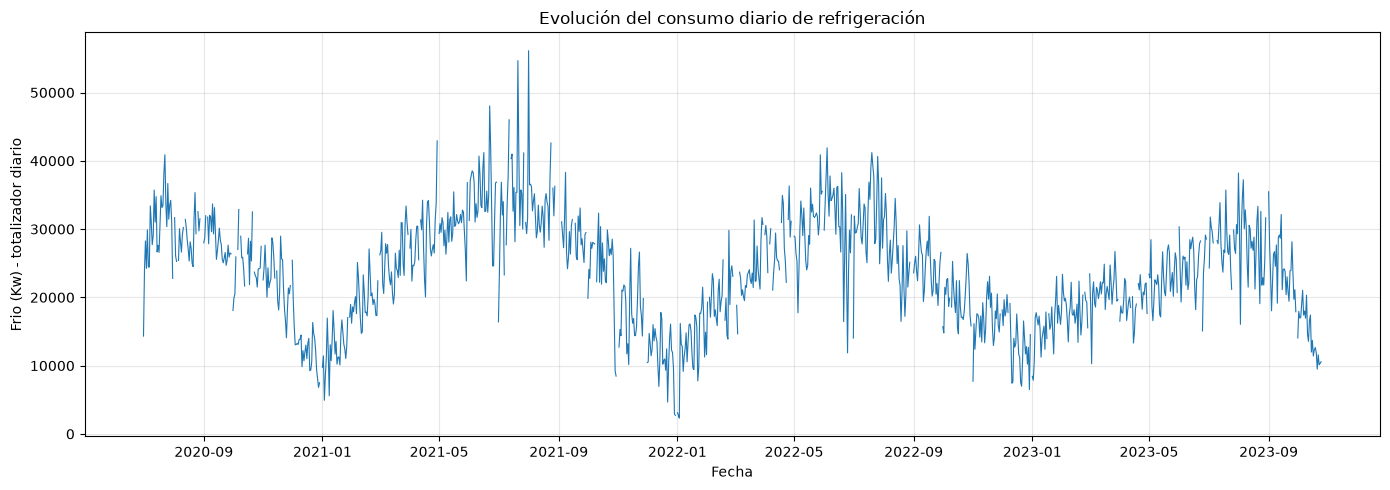

In [23]:

import matplotlib.pyplot as plt

# Crear serie con calendario completo
# Los días faltantes quedarán como NaN
serie_completa = serie.reindex(calendario)

plt.figure(figsize=(14, 5))

plt.plot(
    serie_completa.index,
    serie_completa.values,
    linewidth=0.8
)

plt.title("Evolución del consumo diario de refrigeración")
plt.xlabel("Fecha")
plt.ylabel("Frio (Kw) - totalizador diario")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


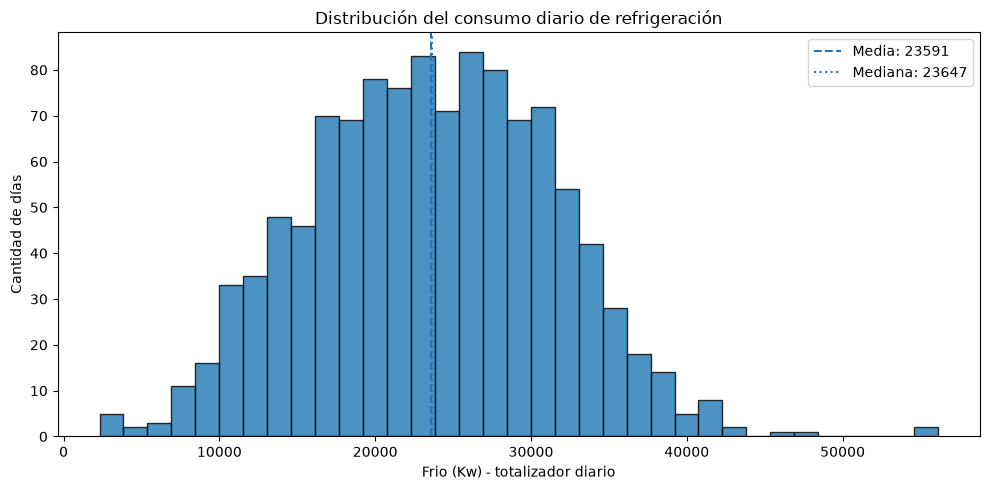

In [24]:

plt.figure(figsize=(10, 5))

plt.hist(
    serie.dropna(),
    bins=35,
    edgecolor="black",
    alpha=0.8
)

plt.axvline(
    serie.mean(),
    linestyle="--",
    label=f"Media: {serie.mean():.0f}"
)

plt.axvline(
    serie.median(),
    linestyle=":",
    label=f"Mediana: {serie.median():.0f}"
)

plt.title("Distribución del consumo diario de refrigeración")
plt.xlabel("Frio (Kw) - totalizador diario")
plt.ylabel("Cantidad de días")
plt.legend()
plt.tight_layout()
plt.show()


### Estadísticas y evolución temporal

- **1.126 días** (01/07/2020–25/10/2023); faltan **86** respecto del calendario.
- **Media:** 23.590,57; **mediana:** 23.647; **desviación estándar:** 7.765,07.
- **74 días** superan 35.000 y requieren revisión.
- La serie muestra mayor consumo en meses cálidos.

Estas cifras describen la selección provisional.


,count,mean,median,std
mes,,,,
1,91,13736.13,14626.0,4026.84
2,78,19368.00,19138.0,3150.75
3,88,23205.98,22501.0,3932.77
4,79,25323.39,25358.0,5754.08
5,90,27680.00,28749.0,5054.17
6,86,30460.48,31116.0,6674.84
7,116,31100.78,30638.5,5936.52
8,108,29182.19,29682.5,5682.57
9,110,26428.46,26355.0,3947.18


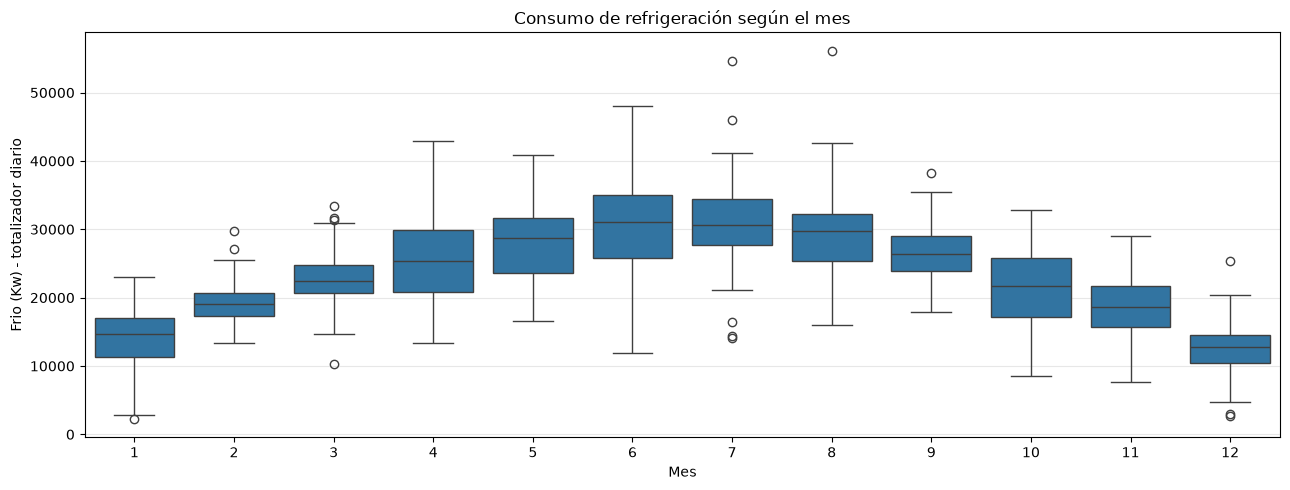

In [25]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Copia para análisis exploratorio
df_eda = diario_provisional[
    ["fecha", "frio_kw"]
].copy()

df_eda["mes"] = df_eda["fecha"].dt.month
df_eda["anio"] = df_eda["fecha"].dt.year
df_eda["dia_semana"] = df_eda["fecha"].dt.day_of_week

# Estadísticas mensuales
resumen_mensual = (
    df_eda.groupby("mes")["frio_kw"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

display(resumen_mensual)

# Boxplot mensual
plt.figure(figsize=(13, 5))

sns.boxplot(
    data=df_eda,
    x="mes",
    y="frio_kw"
)

plt.title("Consumo de refrigeración según el mes")
plt.xlabel("Mes")
plt.ylabel("Frio (Kw) - totalizador diario")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


,count,mean,median
dia_semana,,,
Lunes,164,23282.98,24399.0
Martes,164,23955.74,23911.5
Miércoles,156,24588.49,24639.0
Jueves,158,24072.89,24778.5
Viernes,161,22678.32,22824.0
Sábado,161,23195.02,22886.0
Domingo,162,23400.68,23294.0


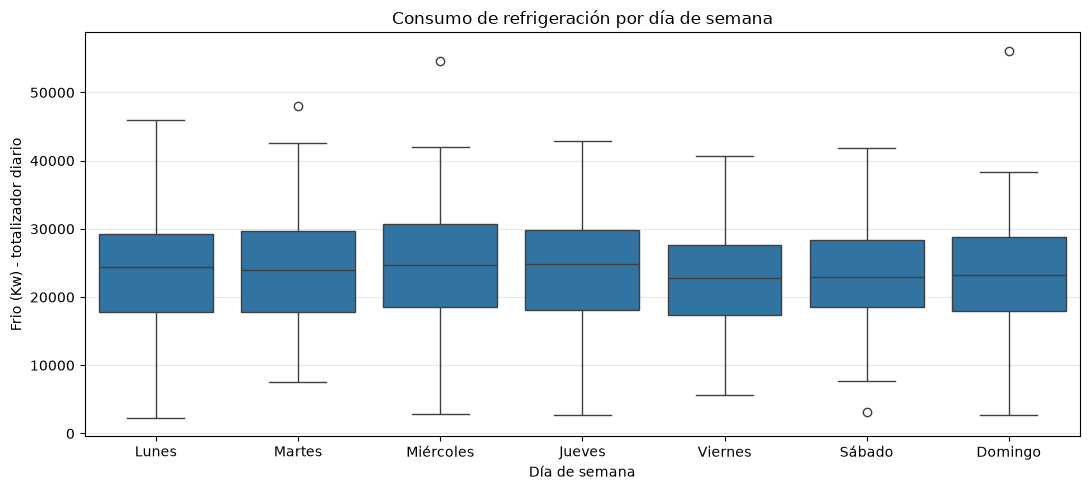

In [26]:

nombres_dias = {
    0: "Lunes",
    1: "Martes",
    2: "Miércoles",
    3: "Jueves",
    4: "Viernes",
    5: "Sábado",
    6: "Domingo"
}

resumen_semanal = (
    df_eda.groupby("dia_semana")["frio_kw"]
    .agg(["count", "mean", "median"])
    .round(2)
)

resumen_semanal.index = (
    resumen_semanal.index.map(nombres_dias)
)

display(resumen_semanal)

plt.figure(figsize=(11, 5))

sns.boxplot(
    data=df_eda,
    x="dia_semana",
    y="frio_kw",
    order=range(7)
)

plt.xticks(
    range(7),
    list(nombres_dias.values())
)

plt.title("Consumo de refrigeración por día de semana")
plt.xlabel("Día de semana")
plt.ylabel("Frio (Kw) - totalizador diario")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Estacionalidad mensual y semanal

- Mayor media mensual: **julio, 31.100,78**; menor: **diciembre, 12.611,77**.
- Por día de semana: máximo **miércoles, 24.588,49**; mínimo **viernes, 22.678,32**.

La variación **mensual** es más marcada que la semanal. La relevancia predictiva se comprobará luego.


In [27]:

from sklearn.linear_model import LinearRegression
import pandas as pd

datos = df_eda[
    ["mes", "dia_semana", "frio_kw"]
].dropna().copy()

y = datos["frio_kw"]

def calcular_r2(columnas):
    # Tratar mes y dia_semana como categorías
    X = pd.get_dummies(
        datos[columnas].astype("category"),
        drop_first=True,
        dtype=int
    )

    modelo = LinearRegression()
    modelo.fit(X, y)

    return modelo.score(X, y)

# Variabilidad explicada por cada variable
r2_mes = calcular_r2(["mes"])
r2_semana = calcular_r2(["dia_semana"])
r2_ambos = calcular_r2(["mes", "dia_semana"])

print(f"R² solo mes: {r2_mes:.4f}")
print(f"R² solo día de semana: {r2_semana:.4f}")
print(f"R² mes + día de semana: {r2_ambos:.4f}")

print(
    "Aporte adicional del día de semana:",
    round(r2_ambos - r2_mes, 4)
)

# Comparar días laborales y fines de semana
datos["fin_semana"] = datos["dia_semana"] >= 5

display(
    datos.groupby("fin_semana")["frio_kw"]
    .agg(["count", "mean", "median"])
    .rename(index={
        False: "Lunes a viernes",
        True: "Sábado y domingo"
    })
    .round(2)
)


R² solo mes: 0.5883
R² solo día de semana: 0.0058
R² mes + día de semana: 0.5941
Aporte adicional del día de semana: 0.0059


,count,mean,median
fin_semana,,,
Lunes a viernes,803,23708.19,23954.0
Sábado y domingo,323,23298.17,23073.0


### Magnitud del efecto calendario

Ajuste lineal **descriptivo dentro de muestra**: **R² mes = 0,5883**; **R² día de semana = 0,0058**; **R² conjunto = 0,5941**.

La media de días laborables supera a la de fines de semana en **1,73 %**. El mes es una candidata clara; el efecto semanal es pequeño y debe evaluarse con validación temporal.


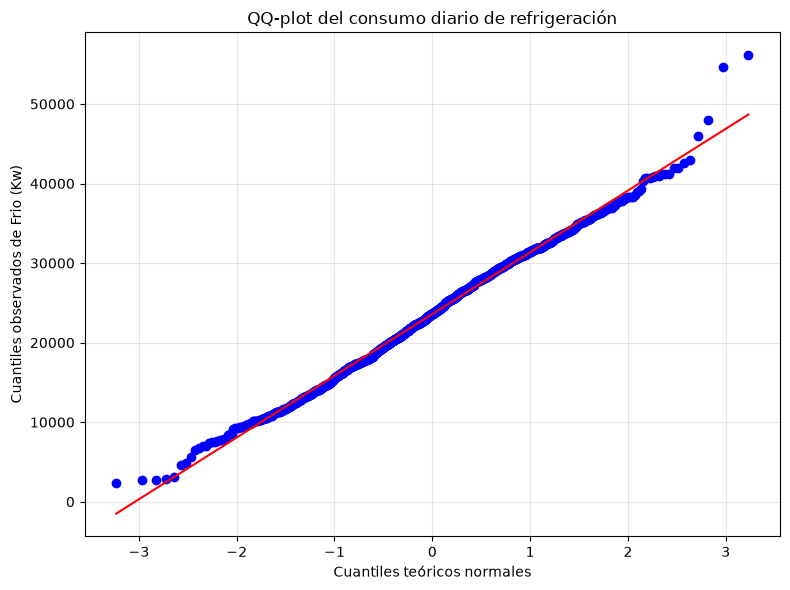

In [28]:

from scipy import stats
import matplotlib.pyplot as plt

# Utilizar los 1.126 consumos diarios provisionales
consumo = diario_provisional["frio_kw"].dropna()

fig, ax = plt.subplots(figsize=(8, 6))

stats.probplot(
    consumo,
    dist="norm",
    plot=ax
)

ax.set_title("QQ-plot del consumo diario de refrigeración")
ax.set_xlabel("Cuantiles teóricos normales")
ax.set_ylabel("Cuantiles observados de Frio (Kw)")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


### QQ-plot del consumo diario

Los cuantiles centrales se aproximan a una normal, pero hay desviaciones en las colas, sobre todo la superior.

No se transforma el objetivo solo por este resultado.


## 6. Predictores del día D y objetivo D+1

Se usan **1.057 pares de fechas consecutivas**; no se salta de D a D+2 cuando falta el día siguiente. La selección de variables sigue siendo exploratoria.


In [29]:
# EDA: correlación de variables eléctricas de hoy
# con el consumo de refrigeración de mañana.

cierres_ee = []

for archivo in archivos:
    df = pd.read_excel(
        archivo,
        sheet_name="Consolidado EE"
    )

    df.columns = df.columns.astype(str).str.strip()

    # Seleccionar registros de las 23:59
    horas = df["HORA"].map(convertir_hora)
    es_cierre = horas == pd.Timedelta(hours=23, minutes=59)
    df = df.loc[es_cierre].copy()
    df["fecha"] = convertir_dia_excel(df["DIA"])

    df["archivo_origen"] = archivo.name

    # Mantener solamente las jornadas provisionales
    df = df.merge(
        diario_provisional[["fecha", "archivo_origen"]],
        on=["fecha", "archivo_origen"],
        how="inner"
    )

    cierres_ee.append(df)

# Unificar los cierres elegidos
df_ee = (
    pd.concat(cierres_ee, ignore_index=True)
    .sort_values("fecha")
    .reset_index(drop=True)
)

# Verificar que exista solo una fila por fecha
assert df_ee["fecha"].is_unique

# Convertir variables eléctricas a números
excluir = {"DIA", "HORA", "fecha", "archivo_origen"}

variables = [
    col for col in df_ee.columns
    if col not in excluir
]

for col in variables:
    df_ee[col] = pd.to_numeric(
        df_ee[col], errors="coerce"
    )

# Consumo de frío del día siguiente
df_ee["target_manana"] = df_ee["Frio (Kw)"].shift(-1)

# Solo asociar días realmente consecutivos
es_manana = (
    df_ee["fecha"].shift(-1) - df_ee["fecha"]
) == pd.Timedelta(days=1)

df_ee.loc[~es_manana, "target_manana"] = float("nan")

# Calcular correlaciones
correlaciones = (
    df_ee[variables + ["target_manana"]]
    .corr()["target_manana"]
    .drop("target_manana")
    .dropna()
    .sort_values(key=lambda x: x.abs(), ascending=False)
)

print("Días totales:", len(df_ee))
print(
    "Pares de días consecutivos:",
    df_ee["target_manana"].notna().sum()
)

print("\n15 mayores correlaciones con el consumo de mañana:")
display(correlaciones.head(15).to_frame("correlacion"))


Días totales: 1126
Pares de días consecutivos: 1057

15 mayores correlaciones con el consumo de mañana:


,correlacion
Frio (Kw),0.842483
Servicios (Kw),0.811387
Elaboracion (Kw),0.597647
Aire (Kw),0.546589
Envasado (Kw),0.522950
Bodega (Kw),0.470549
Linea 4 (Kw),0.455202
Linea 3 (Kw),0.410613
Cocina (Kw),0.377100
Linea 2 (Kw),0.343105


### Variables eléctricas frente a Frío D+1

En **1.057 pares consecutivos**, las principales correlaciones de Pearson fueron `Frio (Kw)` de hoy (**0,8425**), `Servicios (Kw)` (**0,8114**), `Elaboracion (Kw)` (**0,5976**), `Aire (Kw)` (**0,5466**) y `Envasado (Kw)` (**0,5230**).

`Planta (Kw)` y `KW Gral Planta` muestran correlaciones muy bajas por posibles anomalías. Se revisa su calidad antes de seleccionarlas.


In [30]:
# Correlaciones entre producción del día D
# y consumo de frío del día D+1

cierres_produccion = []

for archivo in archivos:

    df = pd.read_excel(
        archivo,
        sheet_name="Consolidado Produccion"
    )

    df.columns = df.columns.astype(str).str.strip()

    # Identificar cierres de las 23:59
    horas = df["HORA"].map(convertir_hora)
    df = df.loc[horas == pd.Timedelta(hours=23, minutes=59)].copy()
    df["fecha"] = convertir_dia_excel(df["DIA"])

    df["archivo_origen"] = archivo.name

    cierres_produccion.append(df)

produccion = pd.concat(
    cierres_produccion,
    ignore_index=True
)

# Identificar combinaciones archivo-fecha con
# exactamente un cierre en la hoja de producción
claves = ["archivo_origen", "fecha"]

n_cierres = produccion.groupby(
    claves
)["HORA"].transform("size")

produccion = produccion.loc[
    n_cierres == 1
].copy()

# Cruzar con nuestros días provisionales
# y con el target del día siguiente
produccion = produccion.merge(
    df_ee[
        ["archivo_origen", "fecha", "target_manana"]
    ],
    on=claves,
    how="inner",
    validate="one_to_one"
)

# Seleccionar columnas numéricas de producción
excluir = {
    "DIA", "HORA", "fecha",
    "archivo_origen", "target_manana"
}

columnas_produccion = [
    col for col in produccion.columns
    if col not in excluir
    and not col.startswith("Unnamed")
    and col != "Hl de Mosto Copia"
]

for col in columnas_produccion:
    produccion[col] = pd.to_numeric(
        produccion[col],
        errors="coerce"
    )

# Correlacionar con consumo de mañana
corr_produccion = (
    produccion[
        columnas_produccion + ["target_manana"]
    ]
    .corr()["target_manana"]
    .drop("target_manana")
    .dropna()
    .sort_values(
        key=lambda s: s.abs(),
        ascending=False
    )
)

print(
    "Fechas cruzadas:",
    len(produccion)
)

print(
    "Pares con target de mañana:",
    produccion["target_manana"].notna().sum()
)

display(
    corr_produccion.to_frame("correlacion")
)


Fechas cruzadas: 1126
Pares con target de mañana: 1057


,correlacion
Hl Producido Bodega,0.559272
Hl Cerveza Envasada,0.482451
Hl Cerveza Filtrada,0.445127
Hl Cerveza L4,0.428207
Hl Cerveza Cocina,0.404367
Hl de Mosto,0.404156
Cocimientos Diarios,0.388883
Hl Cerveza L3,0.351831
Hl Cerveza L2,0.259902
Hl Cerveza L5,0.201922


### Producción frente a Frío D+1

Mayores correlaciones: `Hl Producido Bodega` (**0,5593**), `Hl Cerveza Envasada` (**0,4825**), `Hl Cerveza Filtrada` (**0,4451**) y `Hl Cerveza L4` (**0,4282**).

La producción aporta variables candidatas; su utilidad adicional requiere validación temporal.


In [31]:
# Correlaciones entre los compresores Mycom del día D
# y el consumo de refrigeración del día D+1

cierres_energia = []

for archivo in archivos:

    df = pd.read_excel(
        archivo,
        sheet_name="Totalizadores Energia"
    )

    df.columns = df.columns.astype(str).str.strip()

    # Extraer registros de cierre de jornada
    horas = df["HORA"].map(convertir_hora)
    df = df.loc[horas == pd.Timedelta(hours=23, minutes=59)].copy()
    df["fecha"] = convertir_dia_excel(df["DIA"])

    df["archivo_origen"] = archivo.name

    cierres_energia.append(df)

energia = pd.concat(
    cierres_energia,
    ignore_index=True
)

claves = ["archivo_origen", "fecha"]

# Evitar fechas con varios cierres
n_cierres = energia.groupby(
    claves
)["HORA"].transform("size")

energia = energia.loc[n_cierres == 1].copy()

# Vincular con las jornadas provisionales
energia = energia.merge(
    df_ee[
        ["archivo_origen", "fecha", "target_manana"]
    ],
    on=claves,
    how="inner",
    validate="one_to_one"
)

# Buscar columnas de los compresores
columnas_mycom = [
    col for col in energia.columns
    if "mycom" in col.lower()
]

# Convertir sus valores a numéricos
for col in columnas_mycom:
    energia[col] = pd.to_numeric(
        energia[col],
        errors="coerce"
    )

# Calcular correlaciones
corr_mycom = (
    energia[
        columnas_mycom + ["target_manana"]
    ]
    .corr()["target_manana"]
    .drop("target_manana")
    .sort_values(
        key=lambda s: s.abs(),
        ascending=False
    )
)

print("Fechas cruzadas:", len(energia))
print(
    "Pares con target de mañana:",
    energia["target_manana"].notna().sum()
)

print("\nCorrelaciones de los compresores:")
display(corr_mycom.to_frame("correlacion"))

# Comprobar disponibilidad y variabilidad
resumen_mycom = energia[columnas_mycom].agg(
    ["count", "mean", "std", "min", "max"]
).T

display(resumen_mycom.round(2))


Fechas cruzadas: 1126
Pares con target de mañana: 1057

Correlaciones de los compresores:


,correlacion
KW Mycom 7,0.601891
KW Mycom 5,0.407582
KW Mycom 2,0.376018
KW Mycom 3,0.330106
KW Mycom 6,0.198752
KW Mycom 4,0.196723
KW Mycom 1,0.089293


,count,mean,std,min,max
KW Mycom 1,1126.0,2608.66,3523.24,0.0,12578.0
KW Mycom 2,1126.0,3674.93,2868.34,0.0,12790.0
KW Mycom 3,1126.0,2618.18,2128.73,0.0,8176.0
KW Mycom 4,1126.0,1712.67,2006.94,0.0,9684.0
KW Mycom 5,1126.0,1587.51,2140.28,0.0,17134.0
KW Mycom 6,1126.0,1776.72,1517.92,0.0,4932.0
KW Mycom 7,1126.0,3313.84,2792.01,0.0,26937.0


### Compresores Mycom

Entre los siete compresores, destacan **Mycom 7 (r = 0,6019)**, **Mycom 5 (0,4076)** y **Mycom 2 (0,3760)** frente a Frío D+1.

Revisar valores cero, extremos y redundancia con otros consumos.


In [32]:

# Ranking global de correlaciones
# Variables del día D contra Frio del día D+1

claves = ["archivo_origen", "fecha"]

# Variables eléctricas
base = df_ee[
    claves + ["target_manana"] + variables
].copy()

base = base.rename(columns={
    col: f"EE | {col}"
    for col in variables
})

# Variables de producción
prod = produccion[
    claves + columnas_produccion
].copy()

prod = prod.rename(columns={
    col: f"Produccion | {col}"
    for col in columnas_produccion
})

# Compresores
mycom = energia[
    claves + columnas_mycom
].copy()

mycom = mycom.rename(columns={
    col: f"Mycom | {col}"
    for col in columnas_mycom
})

# Unir por archivo y fecha, nunca por posición
df_global = (
    base
    .merge(prod, on=claves, how="left",
           validate="one_to_one")
    .merge(mycom, on=claves, how="left",
           validate="one_to_one")
    .sort_values("fecha")
    .reset_index(drop=True)
)

# Calcular las correlaciones con el target
numericas = df_global.select_dtypes(
    include="number"
)

ranking_global = (
    numericas.corr()["target_manana"]
    .drop("target_manana")
    .dropna()
    .sort_values(
        key=lambda s: s.abs(),
        ascending=False
    )
)

print("Días analizados:", len(df_global))
print(
    "Pares consecutivos:",
    df_global["target_manana"].notna().sum()
)

print("\n15 variables más correlacionadas:")
display(
    ranking_global.head(15)
    .to_frame("correlacion")
)


Días analizados: 1126
Pares consecutivos: 1057

15 variables más correlacionadas:


,correlacion
EE | Frio (Kw),0.842483
EE | Servicios (Kw),0.811387
Mycom | KW Mycom 7,0.601891
EE | Elaboracion (Kw),0.597647
Produccion | Hl Producido Bodega,0.559272
EE | Aire (Kw),0.546589
EE | Envasado (Kw),0.522950
Produccion | Hl Cerveza Envasada,0.482451
EE | Bodega (Kw),0.470549
EE | Linea 4 (Kw),0.455202


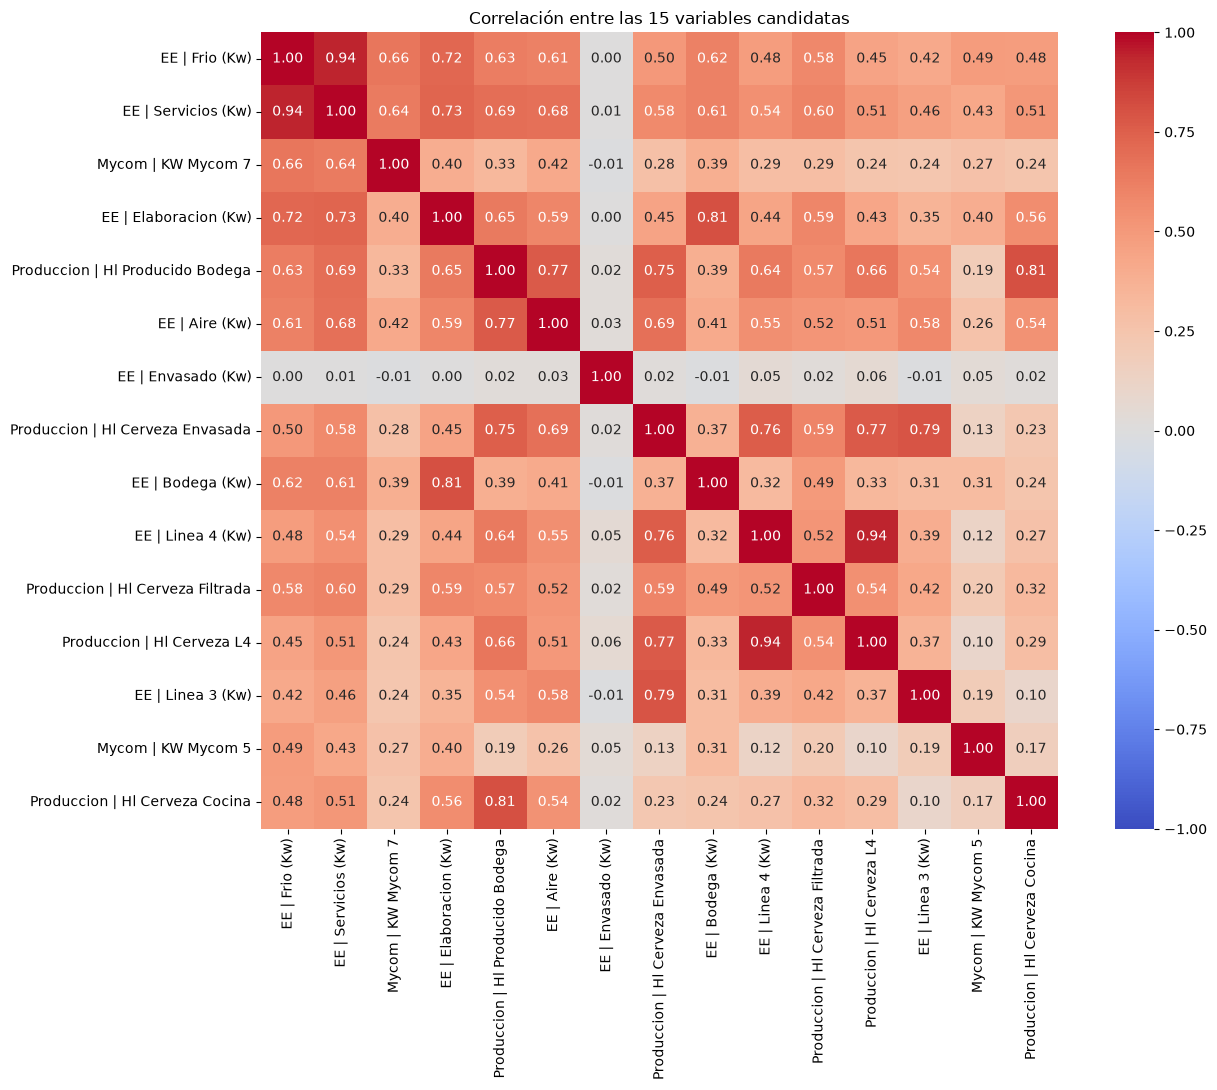

Pares con correlación absoluta >= 0.90:


,variable_1,variable_2,correlacion
1,EE | Linea 4 (Kw),Produccion | Hl Cerveza L4,0.9408
0,EE | Frio (Kw),EE | Servicios (Kw),0.9404


In [33]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Seleccionar las 15 variables más correlacionadas
top15 = ranking_global.head(15).index.tolist()

# Matriz de correlación entre predictores del día D
matriz_corr = df_global[top15].corr()

plt.figure(figsize=(14, 11))

sns.heatmap(
    matriz_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Correlación entre las 15 variables candidatas")
plt.tight_layout()
plt.show()

# Buscar pares con correlación absoluta superior a 0.90
pares_altamente_correlacionados = []

for i in range(len(top15)):
    for j in range(i + 1, len(top15)):
        corr = matriz_corr.iloc[i, j]

        if pd.notna(corr) and abs(corr) >= 0.90:
            pares_altamente_correlacionados.append({
                "variable_1": top15[i],
                "variable_2": top15[j],
                "correlacion": round(corr, 4)
            })

pares_corr = pd.DataFrame(
    pares_altamente_correlacionados
)

print("Pares con correlación absoluta >= 0.90:")

if pares_corr.empty:
    print("No se encontraron pares.")
else:
    display(
        pares_corr.sort_values(
            "correlacion",
            key=lambda s: s.abs(),
            ascending=False
        )
    )


### Multicolinealidad entre predictores

En la matriz inicial (EE, Producción y Mycom) destacan `Frio`–`Servicios` y `Linea 4`–`Hl Cerveza L4`, ambos con **r ≈ 0,94**.

**Atención:** la matriz usa **1.126 días**, mientras que las correlaciones con mañana usan **1.057 pares**. No se eliminan variables solo por correlación alta.


### 6.1. Sensibilidad a valores extremos

Se comprueba cuánto cambia Pearson al excluir temporalmente observaciones anómalas. No se borran datos.


In [34]:
# Investigar el comportamiento de Envasado (Kw)

envasado = "EE | Envasado (Kw)"
frio = "EE | Frio (Kw)"

# Trabajar con las fechas que tienen target de mañana
pares = df_global.loc[
    df_global["target_manana"].notna()
].copy()

print("Días consecutivos:", len(pares))

print("\nCorrelaciones utilizando los mismos días:")

print(
    "Envasado hoy vs. Frío hoy:",
    pares[envasado].corr(pares[frio])
)

print(
    "Envasado hoy vs. Frío mañana:",
    pares[envasado].corr(pares["target_manana"])
)

print(
    "\nEnvasado vs. Frío hoy (todos los días):",
    df_global[envasado].corr(df_global[frio])
)

print("\nDistribución de Envasado:")
display(
    df_global[envasado].describe(
        percentiles=[0.25, 0.50, 0.75, 0.95, 0.99]
    )
)

print("\n10 valores más altos de Envasado:")
display(
    df_global[
        ["fecha", envasado, frio, "target_manana"]
    ].sort_values(
        envasado, ascending=False
    ).head(10)
)

# Impacto de la única observación máxima de Envasado sobre la correlación con frío de hoy

envasado = "EE | Envasado (Kw)"
frio = "EE | Frio (Kw)"

# Correlación con todos los registros
corr_original = df_global[envasado].corr(df_global[frio])

# Excluir temporalmente solo el valor máximo
indice_maximo = df_global[envasado].idxmax()

df_sensibilidad = df_global.drop(index=indice_maximo)

corr_sin_maximo = (
    df_sensibilidad[envasado]
    .corr(df_sensibilidad[frio])
)

print(f"Pearson original: {corr_original:.4f}")
print(f"Pearson sin el máximo: {corr_sin_maximo:.4f}")

print(
    "Spearman original:",
    round(
        df_global[envasado].corr(
            df_global[frio],
            method="spearman"
        ),
        4
    )
)


Días consecutivos: 1057

Correlaciones utilizando los mismos días:
Envasado hoy vs. Frío hoy: 0.5432178966938378
Envasado hoy vs. Frío mañana: 0.5229498735542204

Envasado vs. Frío hoy (todos los días): 0.0028835271792279358

Distribución de Envasado:


count    1.126000e+03
mean     1.807247e+04
std      1.339444e+05
min      3.470000e+02
25%      9.726750e+03
50%      1.632750e+04
75%      1.901975e+04
95%      2.058725e+04
99%      2.121075e+04
max      4.504000e+06
Name: EE | Envasado (Kw), dtype: float64


10 valores más altos de Envasado:


,fecha,EE | Envasado (Kw),EE | Frio (Kw),target_manana
473,2021-11-29,4504000.0,17838.0,NaN
246,2021-03-25,34870.0,24936.0,23214.0
578,2022-03-21,23047.0,31331.0,22352.0
323,2021-06-14,21999.0,33141.0,38963.0
304,2021-05-25,21896.0,32788.0,32508.0
332,2021-06-23,21653.0,42005.0,33261.0
272,2021-04-22,21522.0,27116.0,26058.0
250,2021-03-29,21505.0,30952.0,29214.0
279,2021-04-29,21402.0,42919.0,NaN
560,2022-03-01,21368.0,20542.0,NaN


Pearson original: 0.0029
Pearson sin el máximo: 0.5453
Spearman original: 0.5699


### Valor extremo en Envasado

La correlación con Frío del mismo día cambia de **0,0029** a **0,5453** al excluir temporalmente el registro de **4.504.000 (29/11/2021)**. Spearman con todos los datos es **0,5699**.

Una única anomalía altera fuertemente Pearson. El dato se conserva y se marca para la Fase 2.


In [35]:

# Sensibilidad de la correlación de Mycom 7

variable = "Mycom | KW Mycom 7"

datos = df_global[
    [variable, "target_manana"]
].dropna().copy()

pearson = datos[variable].corr(
    datos["target_manana"],
    method="pearson"
)

spearman = datos[variable].corr(
    datos["target_manana"],
    method="spearman"
)

# Análisis de sensibilidad (NO limpieza definitiva)
limite = datos[variable].quantile(0.99)

datos_sin_extremos = datos.loc[
    datos[variable] <= limite
]

pearson_sensibilidad = (
    datos_sin_extremos[variable]
    .corr(datos_sin_extremos["target_manana"])
)

print(f"Pearson original: {pearson:.4f}")
print(f"Spearman original: {spearman:.4f}")
print(f"Percentil 99 de Mycom 7: {limite:.2f}")
print(
    "Pearson excluyendo temporalmente el 1 % superior:",
    round(pearson_sensibilidad, 4)
)


Pearson original: 0.6019
Spearman original: 0.6468
Percentil 99 de Mycom 7: 6705.00
Pearson excluyendo temporalmente el 1 % superior: 0.6047


**Mycom 7:** se compara Pearson con Spearman y se revisa la influencia del 1 % de valores más altos, sin borrar registros.


## 7. Calidad de los predictores

Se revisan faltantes, ceros, valores extremos y coherencia entre archivos y horas.


In [36]:

# Auditoría general de calidad de los predictores
# No modifica ningún dato original

import numpy as np
import pandas as pd

numericas = df_global.select_dtypes(
    include="number"
).drop(
    columns=["target_manana"],
    errors="ignore"
)

resultados_calidad = []

for columna in numericas.columns:

    s = numericas[columna]

    p99 = s.quantile(0.99)
    maximo = s.max()

    ratio_extremo = (
        maximo / p99
        if pd.notna(p99) and p99 > 0
        else np.nan
    )

    resultados_calidad.append({
        "variable": columna,
        "faltantes_%": round(s.isna().mean() * 100, 2),
        "ceros_%": round((s == 0).mean() * 100, 2),
        "valores_unicos": s.nunique(),
        "desviacion": round(s.std(), 2),
        "p99": round(p99, 2),
        "maximo": round(maximo, 2),
        "maximo_p99": round(ratio_extremo, 2)
    })

calidad = pd.DataFrame(resultados_calidad)

# Mostrar variables que merecen revisión
sospechosas = calidad.loc[
    (calidad["faltantes_%"] > 0)
    | (calidad["ceros_%"] > 50)
    | (calidad["valores_unicos"] <= 1)
    | (calidad["maximo_p99"] > 10)
].copy()

print("Variables numéricas analizadas:", len(calidad))
print("Variables marcadas para revisión:", len(sospechosas))

display(
    sospechosas.sort_values(
        "maximo_p99",
        ascending=False
    )
)


Variables numéricas analizadas: 36
Variables marcadas para revisión: 13


,variable,faltantes_%,ceros_%,valores_unicos,desviacion,p99,maximo,maximo_p99
11,EE | Calderas (Kw),0.00,3.02,585,22320.63,1079.00,524648.0,486.24
4,EE | Envasado (Kw),0.00,0.00,1079,133944.37,21210.75,4504000.0,212.35
17,EE | Restos Planta (Kw),0.00,0.00,1125,151508.50,12737.72,2368897.1,185.97
15,EE | Prod Agua (Kw),0.00,0.00,687,18453.87,1317.75,197630.0,149.98
12,EE | Efluentes (Kw),0.00,0.00,579,3733.71,1184.25,125882.0,106.30
9,EE | Sala Maq (Kw),0.00,0.00,1102,164885.30,48945.75,4208132.0,85.98
14,EE | Pta Agua / Eflu (Kw),0.00,0.00,768,18827.60,2428.75,198770.0,81.84
0,EE | Planta (Kw),0.00,0.00,1126,72016.89,92959.02,2412966.6,25.96
18,EE | KW Gral Planta,0.00,0.00,1112,72048.94,95706.00,2413859.0,25.22
16,EE | Resto Serv (Kw),0.00,0.00,1053,29373.06,11790.12,289142.5,24.52


### Variables con problemas de calidad

De **36 variables iniciales**, **13** requieren revisión por al menos un criterio exploratorio; **10 eléctricas** tienen máximos superiores a **10 × P99**.

- Ceros: `KW Mycom 5` (**54,80 %**) y `Hl Cerveza L5` (**57,64 %**), posiblemente por inactividad.
- Faltantes: `Cocimientos Diarios` (**20,96 %**).

No se eliminan datos antes de distinguir errores de operación normal.


In [37]:

# Investigar fechas de valores extremos
# Sin modificar los datos originales

# Variables con máximos mayores a 10 veces el P99
variables_extremas = calidad.loc[
    calidad["maximo_p99"] > 10,
    "variable"
].tolist()

resultados_extremos = []

for variable in variables_extremas:

    # Fila del valor máximo
    indice = df_global[variable].idxmax()
    fila = df_global.loc[indice]

    p99 = df_global[variable].quantile(0.99)

    resultados_extremos.append({
        "variable": variable,
        "fecha": fila["fecha"],
        "archivo": fila["archivo_origen"],
        "valor_maximo": fila[variable],
        "p99": p99,
        "ratio": fila[variable] / p99
    })

tabla_extremos = pd.DataFrame(
    resultados_extremos
).sort_values("fecha")

display(tabla_extremos)

print("\nCantidad de máximos por fecha:")

display(
    tabla_extremos.groupby("fecha")
    .size()
    .sort_values(ascending=False)
    .to_frame("cantidad_variables")
)


,variable,fecha,archivo,valor_maximo,p99,ratio
7,EE | Resto Serv (Kw),2021-09-10,Totalizadores Planta 2020_2022.xlsx,289142.5,11790.125,24.524125
5,EE | Pta Agua / Eflu (Kw),2021-09-11,Totalizadores Planta 2020_2022.xlsx,198770.0,2428.750,81.840453
6,EE | Prod Agua (Kw),2021-09-11,Totalizadores Planta 2020_2022.xlsx,197630.0,1317.750,149.975337
1,EE | Envasado (Kw),2021-11-29,Totalizadores Planta 2020_2022.xlsx,4504000.0,21210.750,212.345155
2,EE | Sala Maq (Kw),2021-12-24,Totalizadores Planta 2020_2022.xlsx,4208132.0,48945.750,85.975432
0,EE | Planta (Kw),2021-12-29,Totalizadores Planta 2020_2022.xlsx,2412966.6,92959.020,25.957315
8,EE | Restos Planta (Kw),2021-12-29,Totalizadores Planta 2020_2022.xlsx,2368897.1,12737.720,185.974970
9,EE | KW Gral Planta,2021-12-29,Totalizadores Planta 2020_2022.xlsx,2413859.0,95706.000,25.221606
3,EE | Calderas (Kw),2022-01-11,Totalizadores Planta 2020_2022.xlsx,524648.0,1079.000,486.235403
4,EE | Efluentes (Kw),2023-06-26,Totalizadores Planta 2022_2023.xlsx,125882.0,1184.250,106.296812



Cantidad de máximos por fecha:


,cantidad_variables
fecha,
2021-12-29,3
2021-09-11,2
2021-09-10,1
2021-11-29,1
2021-12-24,1
2022-01-11,1
2023-06-26,1


### Fechas con extremos eléctricos

El **29/12/2021**, `Planta`, `KW Gral Planta` y `Restos Planta` superan **2 millones**. El **11/09/2021** destacan `Pta Agua / Eflu` y `Prod Agua`.

**9 de 10 máximos** proceden del Excel 2020–2022. Se comparan con fuentes solapadas y lecturas horarias.


In [38]:
# Investigar anomalías en los registros originales
# Comparando los archivos superpuestos y sus horarios

fechas_revisar = pd.to_datetime([
    "2021-09-11",
    "2021-11-29",
    "2021-12-29"
])

columnas_revisar = [
    "DIA",
    "HORA",
    "Planta (Kw)",
    "KW Gral Planta",
    "Restos Planta (Kw)",
    "Envasado (Kw)",
    "Pta Agua / Eflu (Kw)",
    "Prod Agua (Kw)"
]

resultados = []

for archivo in archivos:

    df = pd.read_excel(
        archivo,
        sheet_name="Consolidado EE",
        usecols=lambda col: (
            str(col).strip() in columnas_revisar
        )
    )

    df.columns = df.columns.astype(str).str.strip()

    df["fecha"] = convertir_dia_excel(df["DIA"])

    df = df.loc[
        df["fecha"].isin(fechas_revisar)
    ].copy()

    # Conservar lecturas cercanas al cierre diario
    horas = df["HORA"].astype(str).str.strip()

    df = df.loc[
        horas.str.contains(
            r"22:00|23:00|23:59",
            regex=True,
            na=False
        )
    ].copy()

    df["archivo_origen"] = archivo.name

    resultados.append(df)

auditoria_originales = pd.concat(
    resultados,
    ignore_index=True
)

for fecha in fechas_revisar:

    print(f"\n{'=' * 65}")
    print("FECHA:", fecha.date())
    print(f"{'=' * 65}")

    caso = auditoria_originales.loc[
        auditoria_originales["fecha"] == fecha
    ]

    display(
        caso.drop(columns=["DIA", "fecha"])
    )



FECHA: 2021-09-11


,HORA,Planta (Kw),Envasado (Kw),Pta Agua / Eflu (Kw),Prod Agua (Kw),Restos Planta (Kw),KW Gral Planta,archivo_origen
0,22:00:00,66979.61,18018.0,198595.0,197545.0,3169.61,69691.0,Totalizadores Planta 2020_2022.xlsx
1,23:00:00,70088.81,18842.0,198683.0,197588.0,3326.81,72924.0,Totalizadores Planta 2020_2022.xlsx
2,23:59:00,73457.04,19602.0,198770.0,197630.0,3469.04,76408.0,Totalizadores Planta 2020_2022.xlsx
9,22:00:00,66979.61,18018.0,198595.0,197545.0,3169.61,69691.0,Totalizadores Planta - 2021_2023.xlsx
10,23:00:00,70088.81,18842.0,198683.0,197588.0,3326.81,72924.0,Totalizadores Planta - 2021_2023.xlsx
11,23:59:00,73457.04,19602.0,198770.0,197630.0,3469.04,76408.0,Totalizadores Planta - 2021_2023.xlsx



FECHA: 2021-11-29


,HORA,Planta (Kw),Envasado (Kw),Pta Agua / Eflu (Kw),Prod Agua (Kw),Restos Planta (Kw),KW Gral Planta,archivo_origen
3,22:00:00,45068.34,4503069.0,1069.0,454.0,-4492947.16,46935.0,Totalizadores Planta 2020_2022.xlsx
4,23:00:00,46988.51,4503506.0,1123.0,471.0,-4492857.49,48949.0,Totalizadores Planta 2020_2022.xlsx
5,23:59:00,48836.68,4504000.0,1179.0,491.0,-4492792.32,50899.0,Totalizadores Planta 2020_2022.xlsx
12,22:00:00,45068.34,4503069.0,1069.0,454.0,-4492947.16,46935.0,Totalizadores Planta - 2021_2023.xlsx
13,23:00:00,46988.51,4503506.0,1123.0,471.0,-4492857.49,48949.0,Totalizadores Planta - 2021_2023.xlsx
14,23:59:00,48836.68,4504000.0,1179.0,491.0,-4492792.32,50899.0,Totalizadores Planta - 2021_2023.xlsx



FECHA: 2021-12-29


,HORA,Planta (Kw),Envasado (Kw),Pta Agua / Eflu (Kw),Prod Agua (Kw),Restos Planta (Kw),KW Gral Planta,archivo_origen
6,22:00:00,51152.52,14297.0,1367.0,478.0,10933.52,51996.0,Totalizadores Planta 2020_2022.xlsx
7,23:00:00,53452.06,15219.0,1420.0,505.0,12327.06,54328.0,Totalizadores Planta 2020_2022.xlsx
8,23:59:00,2412966.60,16408.0,1464.0,523.0,2368897.10,2413859.0,Totalizadores Planta 2020_2022.xlsx
15,22:00:00,51152.52,14297.0,1367.0,478.0,10933.52,51996.0,Totalizadores Planta - 2021_2023.xlsx
16,23:00:00,53452.06,15219.0,1420.0,505.0,12327.06,54328.0,Totalizadores Planta - 2021_2023.xlsx
17,23:59:00,2412966.60,16408.0,1464.0,523.0,2368897.10,2413859.0,Totalizadores Planta - 2021_2023.xlsx


### Comparación entre archivos

Las anomalías del **11/09, 29/11 y 29/12 de 2021** coinciden en los Excel solapados; elegir un archivo más reciente no las resuelve.

Se investigan saltos horarios y relaciones entre totalizadores, sin modificar los datos.


In [39]:
# Investigar los mayores saltos horarios
# en las fechas con anomalías

archivo = next(
    a for a in archivos
    if a.name == "Totalizadores Planta 2020_2022.xlsx"
)

columnas = [
    "Planta (Kw)",
    "Envasado (Kw)",
    "Restos Planta (Kw)",
    "KW Gral Planta",
    "Pta Agua / Eflu (Kw)",
    "Prod Agua (Kw)"
]

df_horario = pd.read_excel(
    archivo,
    sheet_name="Consolidado EE"
)

df_horario["fecha"] = convertir_dia_excel(df_horario["DIA"])
df_horario["hora"] = df_horario["HORA"].map(convertir_hora)

fechas = pd.to_datetime([
    "2021-09-11",
    "2021-11-29",
    "2021-12-29"
])

df_horario = df_horario.loc[
    df_horario["fecha"].isin(fechas)
].sort_values(["fecha", "hora"]).copy()

resultados_saltos = []

for fecha, grupo in df_horario.groupby("fecha"):

    for columna in columnas:

        valores = pd.to_numeric(
            grupo[columna], errors="coerce"
        )

        diferencias = valores.diff()

        if diferencias.notna().any():
            indice = diferencias.abs().idxmax()

            resultados_saltos.append({
                "fecha": fecha.date(),
                "variable": columna,
                "hora": grupo.loc[indice, "HORA"],
                "mayor_salto": diferencias.loc[indice]
            })

tabla_saltos = pd.DataFrame(resultados_saltos)

display(
    tabla_saltos.sort_values(
        ["fecha", "variable"]
    )
)


,fecha,variable,hora,mayor_salto
1,2021-09-11,Envasado (Kw),08:00:00,849.00
3,2021-09-11,KW Gral Planta,21:00:00,3547.00
0,2021-09-11,Planta (Kw),21:00:00,3416.76
5,2021-09-11,Prod Agua (Kw),01:00:00,196652.00
4,2021-09-11,Pta Agua / Eflu (Kw),01:00:00,196698.00
2,2021-09-11,Restos Planta (Kw),16:00:00,160.87
7,2021-11-29,Envasado (Kw),06:00:00,4495423.00
9,2021-11-29,KW Gral Planta,08:00:00,2363.00
6,2021-11-29,Planta (Kw),08:00:00,2280.59
11,2021-11-29,Prod Agua (Kw),08:00:00,23.00


### Saltos horarios anómalos

- **11/09/2021, 01:00:** aumentos de ~**196.000** en `Prod Agua` y `Pta Agua / Eflu`.
- **29/11/2021, 06:00:** `Envasado` sube ~**4,5 millones** y `Restos Planta` baja una magnitud similar.
- **29/12/2021, 23:59:** `Planta`, `KW Gral Planta` y `Restos Planta` suben más de **2,35 millones**.

Son anomalías distintas; el criterio de limpieza se definirá en la Fase 2.


## 8. Agua, gas/vapor y aire comprimido

Se revisan cobertura y correlaciones de estas hojas. La disponibilidad por archivo no equivale a la disponibilidad en toda la serie diaria.


In [40]:
# Exploración de otras áreas de la planta
# Solo lectura: no se modifican los Excel

import pandas as pd

hojas_nuevas = [
    "Consolidado Agua",
    "Consolidado GasVapor",
    "Consolidado Aire"
]

resumen_hojas_adicionales = []
resumen_variables = []

for archivo in archivos:

    with pd.ExcelFile(archivo) as excel:

        for hoja in hojas_nuevas:

            if hoja not in excel.sheet_names:
                print(f"Falta {hoja} en {archivo.name}")
                continue

            df = pd.read_excel(
                excel,
                sheet_name=hoja
            )

            df.columns = (
                df.columns.astype(str).str.strip()
            )

            # Excluir filas auxiliares sin fecha
            if "DIA" not in df.columns:
                print(f"Sin columna DIA: {hoja}")
                continue

            df["fecha_aux"] = convertir_dia_excel(df["DIA"])

            df = df.loc[
                df["fecha_aux"].notna()
            ].copy()

            # Columnas operativas
            excluir = {
                "DIA", "HORA", "fecha_aux", "Id"
            }

            columnas = [
                c for c in df.columns
                if c not in excluir
                and not c.startswith("Unnamed")
            ]

            resumen_hojas_adicionales.append({
                "archivo": archivo.name,
                "hoja": hoja,
                "filas_con_fecha": len(df),
                "variables": len(columnas),
                "fecha_min": df["fecha_aux"].min(),
                "fecha_max": df["fecha_aux"].max()
            })

            for columna in columnas:

                valores = pd.to_numeric(
                    df[columna],
                    errors="coerce"
                )

                resumen_variables.append({
                    "archivo": archivo.name,
                    "hoja": hoja,
                    "variable": columna,
                    "cobertura_%": round(
                        valores.notna().mean() * 100,
                        2
                    ),
                    "valores_unicos": valores.nunique(),
                    "desviacion": round(
                        valores.std(), 2
                    )
                })

tabla_hojas = pd.DataFrame(resumen_hojas_adicionales)
tabla_variables = pd.DataFrame(resumen_variables)

print("RESUMEN DE HOJAS")
display(tabla_hojas)

print("Total de registros de variables analizados:",
      len(tabla_variables))


RESUMEN DE HOJAS


,archivo,hoja,filas_con_fecha,variables,fecha_min,fecha_max
0,Totalizadores Planta 2020_2022.xlsx,Consolidado Agua,15575,16,2020-07-01,2022-03-16
1,Totalizadores Planta 2020_2022.xlsx,Consolidado GasVapor,15575,15,2020-07-01,2022-03-16
2,Totalizadores Planta 2020_2022.xlsx,Consolidado Aire,15575,12,2020-07-01,2022-03-16
3,Totalizadores Planta - 2021_2023.xlsx,Consolidado Agua,15316,22,2021-07-01,2023-03-06
4,Totalizadores Planta - 2021_2023.xlsx,Consolidado GasVapor,15316,18,2021-07-01,2023-03-06
5,Totalizadores Planta - 2021_2023.xlsx,Consolidado Aire,15316,12,2021-07-01,2023-03-06
6,Totalizadores Planta 2022_2023.xlsx,Consolidado Agua,12009,22,2022-07-01,2023-10-26
7,Totalizadores Planta 2022_2023.xlsx,Consolidado GasVapor,12009,18,2022-07-01,2023-10-26
8,Totalizadores Planta 2022_2023.xlsx,Consolidado Aire,12009,12,2022-07-01,2023-10-26


Total de registros de variables analizados: 147


In [41]:

# Resumen de cobertura y variabilidad
# de las nuevas variables

print("VARIABLES POR HOJA")

resumen_por_hoja = (
    tabla_variables
    .groupby("hoja")
    .agg(
        registros_variables=("variable", "size"),
        variables_distintas=("variable", "nunique"),
        cobertura_media=("cobertura_%", "mean"),
        cobertura_minima=("cobertura_%", "min")
    )
    .round(2)
)

display(resumen_por_hoja)

# Variables con cobertura inferior al 70 %
baja_cobertura = tabla_variables.loc[
    tabla_variables["cobertura_%"] < 70
]

print("\nVariables con cobertura inferior al 70 %:")
print("Cantidad:", len(baja_cobertura))

display(
    baja_cobertura.sort_values(
        "cobertura_%"
    ).head(20)
)

# Variables constantes o casi sin variabilidad
poca_variabilidad = tabla_variables.loc[
    tabla_variables["valores_unicos"] <= 2
]

print("\nVariables con 2 o menos valores diferentes:")
print("Cantidad:", len(poca_variabilidad))

display(
    poca_variabilidad.sort_values(
        ["hoja", "variable"]
    ).head(20)
)


VARIABLES POR HOJA


,registros_variables,variables_distintas,cobertura_media,cobertura_minima
hoja,,,,
Consolidado Agua,60,22,100.0,99.99
Consolidado Aire,36,12,100.0,100.00
Consolidado GasVapor,51,19,100.0,99.99



Variables con cobertura inferior al 70 %:
Cantidad: 0


,archivo,hoja,variable,cobertura_%,valores_unicos,desviacion



Variables con 2 o menos valores diferentes:
Cantidad: 1


,archivo,hoja,variable,cobertura_%,valores_unicos,desviacion
106,Totalizadores Planta 2022_2023.xlsx,Consolidado Agua,FC Lavadora L2,100.0,2,1157.41


In [42]:
# Correlaciones de Agua, GasVapor y Aire
# con el consumo de refrigeración del día siguiente

import pandas as pd

hojas_nuevas = [
    "Consolidado Agua",
    "Consolidado GasVapor",
    "Consolidado Aire"
]

claves = ["archivo_origen", "fecha"]

# Usamos los pares consecutivos ya validados
base_nuevas = df_ee.loc[
    df_ee["target_manana"].notna(),
    claves + ["target_manana"]
].copy()

# Horarios esperados de una jornada completa
horarios_esperados = {
    pd.Timedelta(hours=h) for h in range(24)
}
cierre = pd.Timedelta(hours=23, minutes=59)
horarios_esperados.add(cierre)

un_segundo = pd.Timedelta(seconds=1)

for hoja in hojas_nuevas:

    registros_hoja = []

    for archivo in archivos:

        df = pd.read_excel(
            archivo,
            sheet_name=hoja
        )

        df.columns = df.columns.astype(str).str.strip()

        df["fecha"] = convertir_dia_excel(df["DIA"])

        # Convertir horarios a timedelta
        horas = df["HORA"].map(convertir_hora)

        # Normalización exploratoria:
        # corregir únicamente desfases exactos de 1 segundo
        corregir = (horas - un_segundo).isin(
            horarios_esperados
        )

        df["hora_norm"] = horas.where(
            ~corregir,
            horas - un_segundo
        )

        df = df.dropna(subset=["fecha"])

        # Verificar estructura horaria completa
        integridad = (
            df.groupby("fecha")["hora_norm"]
            .agg(
                n_registros="size",
                n_horas="nunique",
                horarios_validos=lambda s:
                    s.isin(horarios_esperados).all()
            )
        )

        fechas_completas = integridad.index[
            (integridad["n_registros"] == 25)
            & (integridad["n_horas"] == 25)
            & integridad["horarios_validos"]
        ]

        # Conservar cierres de jornadas completas
        df = df.loc[
            df["fecha"].isin(fechas_completas)
            & (df["hora_norm"] == cierre)
        ].copy()

        df["archivo_origen"] = archivo.name

        # Variables operativas
        excluir = {
            "DIA", "HORA", "fecha",
            "hora_norm", "archivo_origen", "Id"
        }

        columnas = [
            col for col in df.columns
            if col not in excluir
            and not col.startswith("Unnamed")
            and col != ""
        ]

        # Prefijos para identificar el origen
        df = df[claves + columnas].copy()

        for col in columnas:
            df[col] = pd.to_numeric(
                df[col], errors="coerce"
            )

        df = df.rename(columns={
            col: f"{hoja} | {col}"
            for col in columnas
        })

        registros_hoja.append(df)

    # Unir los archivos de una misma hoja
    datos_hoja = pd.concat(
        registros_hoja,
        ignore_index=True
    )

    assert not datos_hoja.duplicated(claves).any()

    # Cruzar por archivo y fecha
    base_nuevas = base_nuevas.merge(
        datos_hoja,
        on=claves,
        how="left",
        validate="one_to_one"
    )

# Calcular correlaciones con Frío de mañana
variables_nuevas = [
    col for col in base_nuevas.columns
    if col not in claves + ["target_manana"]
]

resultados_corr = []

for variable in variables_nuevas:

    datos = base_nuevas[
        [variable, "target_manana"]
    ].dropna()

    if len(datos) < 200 or datos[variable].nunique() < 2:
        continue

    resultados_corr.append({
        "variable": variable,
        "observaciones": len(datos),
        "cobertura_%": round(
            100 * len(datos) / len(base_nuevas), 2
        ),
        "pearson": datos[variable].corr(
            datos["target_manana"]
        ),
        "spearman": datos[variable].corr(
            datos["target_manana"],
            method="spearman"
        )
    })

ranking_nuevas = pd.DataFrame(resultados_corr)

ranking_nuevas = ranking_nuevas.sort_values(
    "pearson",
    key=lambda s: s.abs(),
    ascending=False
)

print("Pares consecutivos de referencia:", len(base_nuevas))
print("Variables nuevas analizadas:", len(ranking_nuevas))

print("\n15 variables más correlacionadas:")
display(ranking_nuevas.head(15).round(4))


Pares consecutivos de referencia: 1057
Variables nuevas analizadas: 53

15 variables más correlacionadas:


,variable,observaciones,cobertura_%,pearson,spearman
18,Consolidado Agua | Agua Cond Evaporativos,521,49.29,0.7718,0.7894
0,Consolidado Agua | Agua Planta (Hl),1047,99.05,0.7085,0.7302
20,Consolidado Agua | Agua Efluentes,521,49.29,0.5913,0.5813
41,Consolidado Aire | Aire Producido (M3),1047,99.05,0.5732,0.5976
7,Consolidado Agua | Planta de agua (Hl),1047,99.05,0.5260,0.7197
12,Consolidado Agua | Red L3,1047,99.05,0.4898,0.5031
4,Consolidado Agua | Agua Dilucion (Hl),1047,99.05,0.4585,0.4590
44,Consolidado Aire | Aire Envasado (M3),1047,99.05,0.4580,0.4716
3,Consolidado Agua | Agua Cocina (Hl),1047,99.05,0.4549,0.4524
30,Consolidado GasVapor | ET Servicios (Mj),1047,99.05,-0.4516,-0.5085


In [43]:

# Comparar correlaciones originales con
# correlaciones ajustadas por estacionalidad mensual

analisis_estacional = base_nuevas.copy()

analisis_estacional["mes"] = (
    pd.to_datetime(analisis_estacional["fecha"]).dt.month
)

resultados_estacionalidad = []

# Evaluar las 15 variables mejor posicionadas
for variable in ranking_nuevas.head(15)["variable"]:

    datos = analisis_estacional[
        ["mes", variable, "target_manana"]
    ].dropna().copy()

    # Correlación original
    corr_original = datos[variable].corr(
        datos["target_manana"]
    )

    # Quitar el promedio correspondiente a cada mes
    datos["x_ajustada"] = (
        datos[variable]
        - datos.groupby("mes")[variable].transform("mean")
    )

    datos["y_ajustada"] = (
        datos["target_manana"]
        - datos.groupby("mes")["target_manana"].transform("mean")
    )

    corr_ajustada = datos["x_ajustada"].corr(
        datos["y_ajustada"]
    )

    resultados_estacionalidad.append({
        "variable": variable,
        "observaciones": len(datos),
        "pearson_original": corr_original,
        "pearson_ajustado": corr_ajustada
    })

tabla_estacionalidad = pd.DataFrame(
    resultados_estacionalidad
)

print("CORRELACIONES ANTES Y DESPUÉS DEL AJUSTE MENSUAL")

display(
    tabla_estacionalidad.round(4)
)


CORRELACIONES ANTES Y DESPUÉS DEL AJUSTE MENSUAL


,variable,observaciones,pearson_original,pearson_ajustado
0,Consolidado Agua | Agua Cond Evaporativos,521,0.7718,0.4725
1,Consolidado Agua | Agua Planta (Hl),1047,0.7085,0.4812
2,Consolidado Agua | Agua Efluentes,521,0.5913,0.3472
3,Consolidado Aire | Aire Producido (M3),1047,0.5732,0.4490
4,Consolidado Agua | Planta de agua (Hl),1047,0.5260,0.3188
5,Consolidado Agua | Red L3,1047,0.4898,0.2585
6,Consolidado Agua | Agua Dilucion (Hl),1047,0.4585,0.2697
7,Consolidado Aire | Aire Envasado (M3),1047,0.4580,0.3734
8,Consolidado Agua | Agua Cocina (Hl),1047,0.4549,0.3152
9,Consolidado GasVapor | ET Servicios (Mj),1047,-0.4516,-0.1277


### Efecto de la estacionalidad en las correlaciones

Se analizaron **53 variables adicionales**. Al descontar el promedio mensual, mantienen asociaciones moderadas `Agua Planta`, `Agua Cond Evaporativos`, `Aire Producido` y `Vapor Envasado`.

La relación negativa de `ET Servicios` y `Vapor Servicio` se debilita. `Agua Cond Evaporativos` solo cubre **49,3 %** de los pares diarios.


In [44]:
# Correlación parcial: controlar Frío de hoy y mes
# Análisis descriptivo, sin entrenar modelos predictivos

import numpy as np
import pandas as pd

variables_elegidas = [
    "Consolidado Agua | Agua Cond Evaporativos",
    "Consolidado Agua | Agua Planta (Hl)",
    "Consolidado Aire | Aire Producido (M3)",
    "Consolidado GasVapor | Vapor Envasado (Kg)",
    "Consolidado Aire | Aire Planta (M3)",
    "Consolidado GasVapor | ET Servicios (Mj)",
    "Consolidado GasVapor | Vapor Servicio (Kg)"
]

frio_hoy = "EE | Frio (Kw)"

# Incorporar el consumo de frío del día D
base_parcial = base_nuevas.merge(
    df_global[["archivo_origen", "fecha", frio_hoy]],
    on=["archivo_origen", "fecha"],
    how="left",
    validate="one_to_one"
)

base_parcial["mes"] = pd.to_datetime(
    base_parcial["fecha"]
).dt.month

resultados_parciales = []

for variable in variables_elegidas:

    datos = base_parcial[
        [variable, frio_hoy, "target_manana", "mes"]
    ].dropna().copy()

    # Variables de control: Frío de hoy + mes del año
    meses = pd.get_dummies(
        datos["mes"],
        drop_first=True,
        dtype=float
    )

    controles = np.column_stack([
        np.ones(len(datos)),
        datos[frio_hoy].to_numpy(dtype=float),
        meses.to_numpy(dtype=float)
    ])

    x = datos[variable].to_numpy(dtype=float)
    y = datos["target_manana"].to_numpy(dtype=float)

    # Quitar de X e Y la parte explicada linealmente
    # por Frío de hoy y por el mes
    coef_x = np.linalg.lstsq(
        controles, x, rcond=None
    )[0]

    coef_y = np.linalg.lstsq(
        controles, y, rcond=None
    )[0]

    residuo_x = x - controles @ coef_x
    residuo_y = y - controles @ coef_y

    corr_parcial = np.corrcoef(
        residuo_x, residuo_y
    )[0, 1]

    resultados_parciales.append({
        "variable": variable,
        "observaciones": len(datos),
        "pearson_original": np.corrcoef(x, y)[0, 1],
        "pearson_parcial": corr_parcial
    })

tabla_parcial = pd.DataFrame(resultados_parciales)

display(
    tabla_parcial.round(4)
)


,variable,observaciones,pearson_original,pearson_parcial
0,Consolidado Agua | Agua Cond Evaporativos,521,0.7718,0.1678
1,Consolidado Agua | Agua Planta (Hl),1047,0.7085,0.1356
2,Consolidado Aire | Aire Producido (M3),1047,0.5732,0.1563
3,Consolidado GasVapor | Vapor Envasado (Kg),1047,0.4451,0.2372
4,Consolidado Aire | Aire Planta (M3),1047,0.4342,0.2022
5,Consolidado GasVapor | ET Servicios (Mj),1047,-0.4516,-0.1078
6,Consolidado GasVapor | Vapor Servicio (Kg),1047,-0.4299,-0.0655


### Correlaciones parciales

Tras controlar linealmente **Frío de hoy y mes**, las mayores correlaciones parciales entre las variables adicionales analizadas son `Vapor Envasado` (**0,2372**) y `Aire Planta` (**0,2022**).

`Agua Cond Evaporativos` cae de **0,7718** a **0,1678**; `Agua Planta`, de **0,7079** a **0,1321**. Parte de su asociación original es compartida con los controles.

Estas correlaciones no garantizan una mejora predictiva.


In [45]:

# Ranking conjunto de todas las variables exploradas

claves = ["archivo_origen", "fecha"]

# Variables adicionales de Agua, GasVapor y Aire
columnas_adicionales = [
    c for c in base_nuevas.columns
    if c not in claves + ["target_manana"]
]

# Integrar las variables nuevas al dataset exploratorio
df_completo = df_global.merge(
    base_nuevas[claves + columnas_adicionales],
    on=claves,
    how="left",
    validate="one_to_one"
)

# Conservar únicamente los pares D -> D+1
pares = df_completo.loc[
    df_completo["target_manana"].notna()
].copy()

# Seleccionar variables numéricas
columnas_numericas = (
    pares.select_dtypes(include="number")
    .columns.drop("target_manana")
)

resultados = []

for variable in columnas_numericas:

    datos = pares[
        [variable, "target_manana"]
    ].dropna()

    if len(datos) < 200:
        continue

    if datos[variable].nunique() < 2:
        continue

    resultados.append({
        "variable": variable,
        "observaciones": len(datos),
        "cobertura_%": 100 * len(datos) / len(pares),
        "pearson": datos[variable].corr(
            datos["target_manana"]
        ),
        "spearman": datos[variable].corr(
            datos["target_manana"],
            method="spearman"
        )
    })

ranking_final = (
    pd.DataFrame(resultados)
    .sort_values(
        "pearson",
        key=lambda s: s.abs(),
        ascending=False
    )
    .reset_index(drop=True)
)

print("Pares consecutivos:", len(pares))
print("Variables evaluadas:", len(ranking_final))

print("\nTOP 15 GLOBAL")
display(ranking_final.head(15).round(4))


Pares consecutivos: 1057
Variables evaluadas: 89

TOP 15 GLOBAL


,variable,observaciones,cobertura_%,pearson,spearman
0,EE | Frio (Kw),1057,100.0000,0.8425,0.8561
1,EE | Servicios (Kw),1057,100.0000,0.8114,0.8308
2,Consolidado Agua | Agua Cond Evaporativos,521,49.2904,0.7718,0.7894
3,Consolidado Agua | Agua Planta (Hl),1047,99.0539,0.7085,0.7302
4,Mycom | KW Mycom 7,1057,100.0000,0.6019,0.6468
5,EE | Elaboracion (Kw),1057,100.0000,0.5976,0.5933
6,Consolidado Agua | Agua Efluentes,521,49.2904,0.5913,0.5813
7,Consolidado Aire | Aire Producido (M3),1047,99.0539,0.5732,0.5976
8,Produccion | Hl Producido Bodega,1057,100.0000,0.5593,0.5791
9,EE | Aire (Kw),1057,100.0000,0.5466,0.5694


### Ranking global de correlaciones

Se evaluaron **89 variables** sobre **1.057 pares D → D+1**. Lideran `Frio` actual (**0,8425**), `Servicios` (**0,8114**), `Agua Cond Evaporativos` (**0,7718**) y `Agua Planta` (**0,7085**).

Los coeficientes usan distintas cantidades de observaciones según cobertura. El ranking identifica candidatas, **no selecciona automáticamente variables**.


### Scatter plots: Top 5 global

Cada gráfico usa los pares disponibles para esa variable; `Agua Cond Evaporativos` tiene menor cobertura. Son gráficos descriptivos.


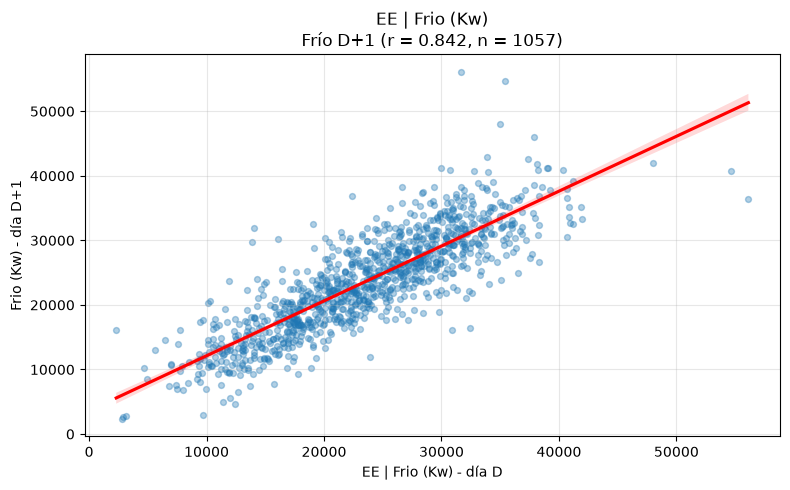

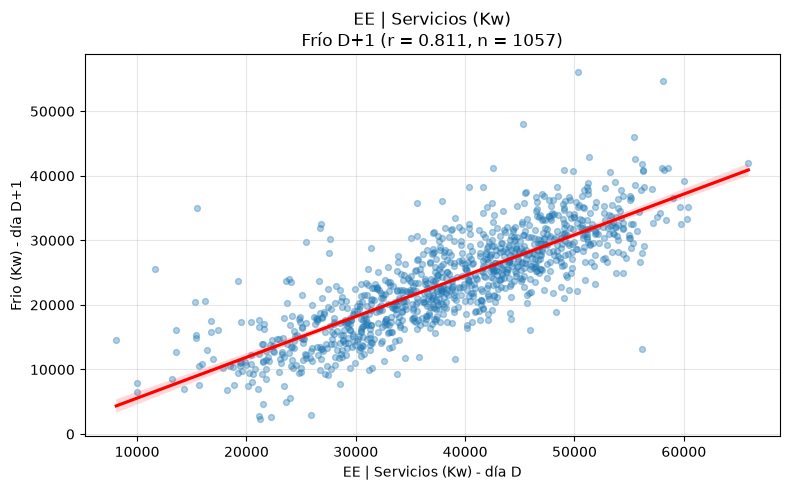

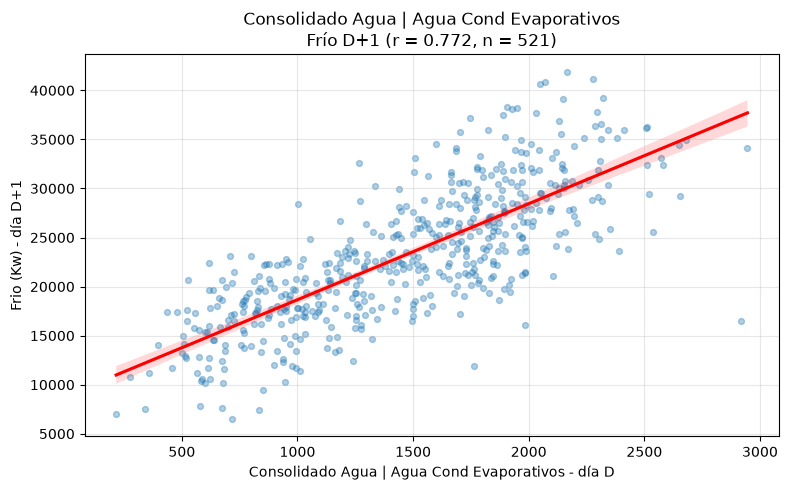

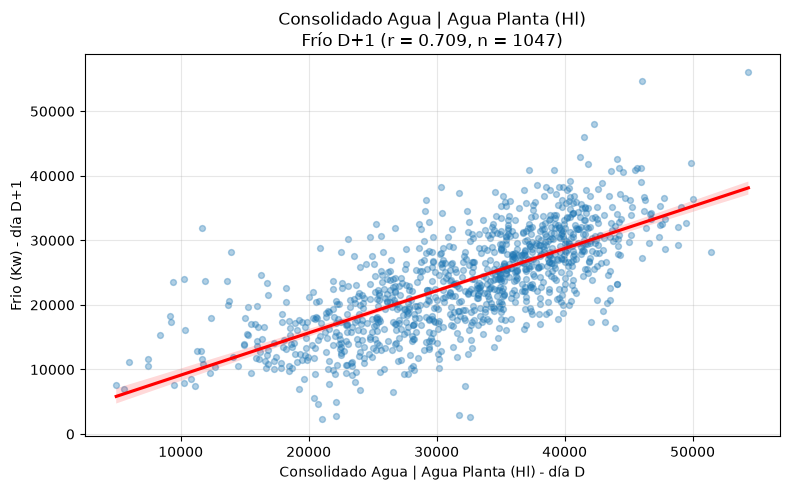

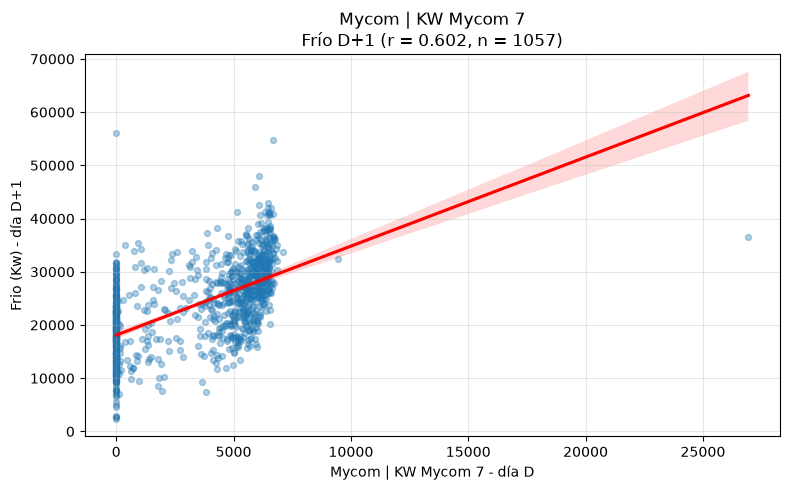

In [46]:
# Scatter plots de las 5 variables más correlacionadas del ranking GLOBAL
# Se calcula a partir del dataframe unido con todas las áreas.

import matplotlib.pyplot as plt
import seaborn as sns

top5_global = ranking_final.head(5)["variable"].tolist()

for variable in top5_global:
    datos_grafico = pares[[variable, "target_manana"]].dropna()
    corr = datos_grafico[variable].corr(datos_grafico["target_manana"])

    plt.figure(figsize=(8, 5))
    sns.regplot(
        data=datos_grafico,
        x=variable,
        y="target_manana",
        scatter_kws={"alpha": 0.35, "s": 18},
        line_kws={"color": "red"}
    )
    plt.title(f"{variable}\nFrío D+1 (r = {corr:.3f}, n = {len(datos_grafico)})")
    plt.xlabel(f"{variable} - día D")
    plt.ylabel("Frio (Kw) - día D+1")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


In [47]:

# Comparación anual del consumo eléctrico por área

columnas_areas = [
    "EE | Frio (Kw)",
    "EE | Servicios (Kw)",
    "EE | Elaboracion (Kw)",
    "EE | Envasado (Kw)",
    "EE | Bodega (Kw)",
    "EE | Aire (Kw)"
]

# Conservar las columnas disponibles
columnas_areas = [
    c for c in columnas_areas
    if c in df_global.columns
]

# Trabajar con una observación por fecha
assert not df_global["fecha"].duplicated().any()

df_areas = df_global[
    ["fecha"] + columnas_areas
].copy()

df_areas["anio"] = pd.to_datetime(
    df_areas["fecha"]
).dt.year

# Cobertura disponible por año
cobertura_anual = (
    df_areas.groupby("anio")
    .agg(
        dias_disponibles=("fecha", "nunique"),
        primera_fecha=("fecha", "min"),
        ultima_fecha=("fecha", "max")
    )
)

print("COBERTURA POR AÑO")
display(cobertura_anual)

# Transformar para comparar áreas
areas_largo = df_areas.melt(
    id_vars=["fecha", "anio"],
    value_vars=columnas_areas,
    var_name="area",
    value_name="consumo"
)

resumen_anual = (
    areas_largo.groupby(["anio", "area"])
    .agg(
        observaciones=("consumo", "count"),
        promedio=("consumo", "mean"),
        mediana=("consumo", "median"),
        maximo=("consumo", "max")
    )
    .reset_index()
)

print("\nMEDIANA DIARIA POR ÁREA Y AÑO")

tabla_medianas = resumen_anual.pivot(
    index="area",
    columns="anio",
    values="mediana"
)

display(tabla_medianas.round(2))

print("\nPROMEDIO DIARIO POR ÁREA Y AÑO")

tabla_promedios = resumen_anual.pivot(
    index="area",
    columns="anio",
    values="promedio"
)

display(tabla_promedios.round(2))


COBERTURA POR AÑO


,dias_disponibles,primera_fecha,ultima_fecha
anio,,,
2020,165,2020-07-01,2020-12-29
2021,339,2021-01-01,2021-12-30
2022,342,2022-01-01,2022-12-30
2023,280,2023-01-01,2023-10-25



MEDIANA DIARIA POR ÁREA Y AÑO


anio,2020,2021,2022,2023
area,,,,
EE | Aire (Kw),7313.00,6752.0,6808.00,5511.0
EE | Bodega (Kw),6124.50,6000.5,6285.75,5995.0
EE | Elaboracion (Kw),7260.25,6955.5,7290.25,6999.0
EE | Envasado (Kw),16187.00,16942.0,14689.50,16627.0
EE | Frio (Kw),25745.00,26715.0,22710.00,21165.0
EE | Servicios (Kw),42713.00,43094.0,37968.00,35249.0



PROMEDIO DIARIO POR ÁREA Y AÑO


anio,2020,2021,2022,2023
area,,,,
EE | Aire (Kw),7065.22,6603.38,6657.81,5436.03
EE | Bodega (Kw),6012.86,5666.84,6172.12,5912.06
EE | Elaboracion (Kw),6975.68,6598.40,7252.57,6923.63
EE | Envasado (Kw),15070.46,28705.52,13375.43,12705.01
EE | Frio (Kw),24517.44,25178.21,23111.73,21707.08
EE | Servicios (Kw),40985.92,41024.33,37919.26,35018.25


### Consumo eléctrico por área y año

Días disponibles: **2020: 165**, **2021: 339**, **2022: 342**, **2023: 280**. Los años **2020 y 2023 son parciales**; no se comparan como tendencias anuales equivalentes.

Medianas de Frío: **25.745**, **26.715**, **22.710** y **21.165**, respectivamente. En `Envasado` (2021), **media 28.705,52** vs. **mediana 16.942**: los valores extremos elevan el promedio.

No se suman agregados eléctricos con sus posibles componentes.


## 9. Trazabilidad: SHA-256

`notebooks/SHA256SUMS.txt` registra los hashes de los **tres Excel**. El notebook también genera `data/consolidado_ee_unificado_inicial.csv` (**43.515 × 23**) y guarda **cuatro hashes** en `data/checksums.json`.

El CSV une **solo `Consolidado EE`**, sin limpieza; no es el dataset multivariable final. Se usa **SHA-256 y no MD5** por su mayor resistencia a colisiones. Reproducir el hash del CSV exige conservar las reglas y versiones de exportación.


In [48]:

# Calcular SHA-256 de los archivos originales

import hashlib
import pandas as pd

resultados_hash = []

for archivo in archivos:

    sha256 = hashlib.sha256()

    with open(archivo, "rb") as f:
        for bloque in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            sha256.update(bloque)

    resultados_hash.append({
        "archivo": archivo.name,
        "tamano_MB": round(
            archivo.stat().st_size / (1024 ** 2),
            2
        ),
        "sha256": sha256.hexdigest()
    })

tabla_hash = pd.DataFrame(resultados_hash)

display(tabla_hash)

print(
    "Archivos originales verificados:",
    len(tabla_hash)
)

print(
    "Hashes SHA-256 únicos:",
    tabla_hash["sha256"].nunique()
)


,archivo,tamano_MB,sha256
0,Totalizadores Planta 2020_2022.xlsx,30.00,7bb3474c1686712eed9634b1afc757540766dad56c1558...
1,Totalizadores Planta - 2021_2023.xlsx,33.09,b4dbfacd0fd8d7720ec6dfc09dc593fac479d78a7c17ea...
2,Totalizadores Planta 2022_2023.xlsx,25.95,aba9f9ff11e6fa477af282f14a88354f8a55c782941d5a...


Archivos originales verificados: 3
Hashes SHA-256 únicos: 3


In [49]:
# Verificar el manifiesto SHA-256 ya guardado en notebooks/
# No sobrescribe los hashes existentes

manifiesto = ROOT / "notebooks" / "SHA256SUMS.txt"

if not manifiesto.is_file():
    print(f"No se encontró el manifiesto: {manifiesto}")
    print("Guardá en esa ruta los hashes calculados para poder verificarlos.")
else:
    hashes_guardados = {}
    for linea in manifiesto.read_text(encoding="utf-8").splitlines():
        if not linea.strip() or linea.lstrip().startswith("#"):
            continue
        piezas = linea.strip().split(maxsplit=1)
        if len(piezas) != 2:
            raise ValueError(f"Línea no reconocida en {manifiesto}: {linea!r}")
        hash_guardado, nombre_archivo = piezas
        hashes_guardados[nombre_archivo.lstrip("* ")] = hash_guardado.lower()

    verificacion = tabla_hash[["archivo", "sha256"]].copy()
    verificacion["hash_guardado"] = verificacion["archivo"].map(hashes_guardados)
    verificacion["coincide"] = (
        verificacion["sha256"] == verificacion["hash_guardado"]
    )
    display(verificacion[["archivo", "coincide"]])
    assert verificacion["coincide"].all(), "Los hashes no coinciden con el manifiesto."
    print("Los tres Excel coinciden con el manifiesto guardado.")


,archivo,coincide
0,Totalizadores Planta 2020_2022.xlsx,True
1,Totalizadores Planta - 2021_2023.xlsx,True
2,Totalizadores Planta 2022_2023.xlsx,True


Los tres Excel coinciden con el manifiesto guardado.


In [50]:

# Versionado del consolidado inicial de electricidad
# No se modifican los archivos Excel originales

from pathlib import Path
import pandas as pd
import hashlib
import json

raiz = Path.cwd()
if raiz.name.lower() == "notebooks":
    raiz = raiz.parent

carpeta_datos = raiz / "data"
assert carpeta_datos.is_dir()

# Unificar la hoja principal de los tres archivos,
# conservando registros duplicados y anómalos
partes = []

archivos_ordenados = sorted(
    [Path(a) for a in archivos],
    key=lambda p: p.name
)

for archivo in archivos_ordenados:
    df = pd.read_excel(
        archivo,
        sheet_name="Consolidado EE"
    )

    df.columns = df.columns.astype(str).str.strip()

    df.insert(0, "archivo_origen", archivo.name)
    df.insert(1, "fila_excel", range(2, len(df) + 2))

    partes.append(df)

unificado_inicial = pd.concat(
    partes, ignore_index=True, sort=False
)

ruta_csv = carpeta_datos / "consolidado_ee_unificado_inicial.csv"
unificado_inicial.to_csv(
    ruta_csv,
    index=False,
    encoding="utf-8",
    lineterminator="\n"
)

# Calcular SHA-256 leyendo por bloques
def huella(ruta):
    sha = hashlib.sha256()
    with open(ruta, "rb") as f:
        for bloque in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            sha.update(bloque)
    return sha.hexdigest()

# Registrar tanto los Excel como el consolidado inicial
checksums = {
    f"data/{archivo.name}": huella(archivo)
    for archivo in archivos_ordenados
}

checksums[
    f"data/{ruta_csv.name}"
] = huella(ruta_csv)

ruta_json = carpeta_datos / "checksums.json"

with open(ruta_json, "w", encoding="utf-8") as f:
    json.dump(
        checksums, f, indent=2, ensure_ascii=False,
        sort_keys=True
    )

print("Dimensiones:", unificado_inicial.shape)
print("Archivo unificado:", ruta_csv)
print("Manifiesto:", ruta_json)
print("Checksums registrados:", len(checksums))


Dimensiones: (43515, 23)
Archivo unificado: c:\Users\maxim\OneDrive\Desktop\tp-final\data\consolidado_ee_unificado_inicial.csv
Manifiesto: c:\Users\maxim\OneDrive\Desktop\tp-final\data\checksums.json
Checksums registrados: 4


In [51]:
# Verificar que data/checksums.json coincide con los cuatro archivos reales
with ruta_json.open("r", encoding="utf-8") as f:
    checksums_almacenados = json.load(f)

verificacion_json = pd.DataFrame([
    {
        "archivo": nombre,
        "existe": (raiz / nombre).is_file(),
        "coincide": (raiz / nombre).is_file() and huella(raiz / nombre) == hash_esperado,
    }
    for nombre, hash_esperado in checksums_almacenados.items()
])

display(verificacion_json)
assert len(verificacion_json) == 4 and verificacion_json["coincide"].all()
print("Los cuatro SHA-256 coinciden con data/checksums.json.")


,archivo,existe,coincide
0,data/Totalizadores Planta - 2021_2023.xlsx,True,True
1,data/Totalizadores Planta 2020_2022.xlsx,True,True
2,data/Totalizadores Planta 2022_2023.xlsx,True,True
3,data/consolidado_ee_unificado_inicial.csv,True,True


Los cuatro SHA-256 coinciden con data/checksums.json.


## 10. Conclusiones y próximos pasos


### Conclusiones del EDA

**Calidad temporal.** Serie provisional de **1.126 días** sobre **1.212**: faltan **86** (23 sin fecha etiquetada, 63 excluidos). Se detectaron **5 cierres conflictivos**, **587 desfases de un segundo**, **2 reinicios incorrectos** y **26 jornadas con descensos**. Hay **31 fechas candidatas** a recuperación; requieren validación.

**Consumo.** Fuerte estacionalidad mensual (**R² = 0,5883**) y efecto semanal bajo (**R² = 0,0058**), medidos dentro de muestra. La distribución es aproximadamente normal en el centro, con desvíos en las colas. Las comparaciones anuales están limitadas por períodos parciales y outliers.

**Predictores.** Sobre **1.057 pares consecutivos** se evaluaron **89 variables**. Las mayores correlaciones con Frío de mañana corresponden a Frío de hoy (**0,8425**), Servicios (**0,8114**), Agua Cond Evaporativos (**0,7718; 49,3 % de cobertura**) y Agua Planta (**0,7085**). Las correlaciones son exploratorias; hay redundancia y valores extremos.

**Trazabilidad.** Se verificaron los tres Excel con SHA-256 y se registró el consolidado inicial de `Consolidado EE` en `data/checksums.json`. Aún **no** es el dataset multivariable limpio.

### Pendiente para la Fase 2

- Resolver fechas mal etiquetadas, duplicados y cierres conflictivos con reglas reproducibles.
- Evaluar la corrección de desfases horarios y controlar reinicios, descensos, faltantes y outliers, sin descartar automáticamente cierres válidos.
- Construir el dataset **multivariable diario**, con objetivo **D+1** solo para fechas consecutivas y linaje documentado.
- Comparar **Frío actual + calendario** con conjuntos ampliados; seleccionar variables y validar **cronológicamente**, sin utilizar información futura.
- Confirmar la unidad física de `Frio (Kw)` como totalizador acumulado.

**Alcance:** este EDA no limpia definitivamente los datos ni evalúa modelos fuera de muestra.
